In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()
df = pd.read_csv('ONINE_FOOD_DELIVERY_ANALYSIS.csv')



Saving ONINE_FOOD_DELIVERY_ANALYSIS.csv to ONINE_FOOD_DELIVERY_ANALYSIS.csv


In [ ]:
df

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,NaN,NaN,Mumbai,NaN,RES295,Restaurant_500,Arabian,6/10/2024,...,132.0,Card,Delivered,NaN,DP835,2.0,4.0,Weekday,True,0.17
99996,ORD099997,CUST6158,NaN,Male,Mumbai,East,RES157,Restaurant_458,Arabian,4/22/2024,...,1078.0,NaN,Delivered,NaN,DP476,4.0,3.5,Weekday,False,-0.15
99997,ORD099998,CUST2155,NaN,NaN,Delhi,East,RES287,Restaurant_273,NaN,2/23/2024,...,NaN,COD,Cancelled,NaN,DP577,2.0,4.0,Weekday,True,0.47
99998,ORD099999,CUST3015,NaN,Female,Delhi,North,RES491,Restaurant_241,NaN,12/10/2024,...,NaN,NaN,Delivered,NaN,DP896,NaN,4.3,Weekday,NaN,0.44


In [ ]:
import pandas as pd
import numpy as np

df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%m/%d/%Y", errors="coerce")
df["Order_Weekday"] = df["Order_Date"].dt.day_name()
df["Order_Month"] = df["Order_Date"].dt.month

df = df.dropna(subset=["Order_Date"]).copy()
df = df.drop(columns=["Order_Time"], errors="ignore")

# Define cancelled here so it can be safely used throughout the script
cancelled = df["Order_Status"].str.strip().str.title() == "Cancelled"

cat_cols = ["Customer_Gender", "City", "Area", "Cuisine_Type",
            "Payment_Mode", "Order_Status", "Cancellation_Reason", "Order_Day"]
for c in cat_cols:
    df[c] = df[c].str.strip().str.title()
    df["Payment_Mode"] = df["Payment_Mode"].replace({"Cod": "COD", "Upi": "UPI", "Card" : "CARD", "Wallet" :  "WALLET" })

df["Restaurant_Rating"] = df["Restaurant_Rating"].clip(upper=5)
df["Delivery_Rating"] = df["Delivery_Rating"].clip(1, 5)
df["Profit_Margin"] = df["Profit_Margin"].clip(lower=0)


df["Discount_Applied"] = df["Discount_Applied"].fillna(df["Order_Value"] - df["Final_Amount"])
df["Order_Value"] = df["Order_Value"].fillna(df["Final_Amount"].fillna(0) + df["Discount_Applied"].fillna(0))
df["Discount_Applied"] = df["Discount_Applied"].clip(upper=df["Order_Value"])
df["Final_Amount"] = df["Final_Amount"].fillna(df["Order_Value"] - df["Discount_Applied"])

df.loc[df["Final_Amount"] < 0, "Final_Amount"] = df["Order_Value"] - df["Discount_Applied"]

for c in ["Customer_Age", "Distance_km", "Order_Value", "Discount_Applied"]:
    df[c] = df[c].fillna(df[c].median())

df.loc[~cancelled, "Delivery_Time_Min"] = df.loc[~cancelled, "Delivery_Time_Min"].fillna(df["Delivery_Time_Min"].median())
df.loc[~cancelled, "Delivery_Rating"] = df.loc[~cancelled, "Delivery_Rating"].fillna(df["Delivery_Rating"].median())

for c in ["Customer_Gender", "City", "Area", "Cuisine_Type", "Payment_Mode"]:
    df[c] = df[c].fillna("Unknown")
df["Final_Amount"] = df["Final_Amount"].fillna(df["Order_Value"] - df["Discount_Applied"])

df["Cancellation_Reason"] = df["Cancellation_Reason"].fillna("Not Applicable")
df["Peak_Hour"] = (
    df["Peak_Hour"].astype("object").map({True: "Yes", False: "No"}).fillna("Unknown")
)

c = "Delivery_Time_Min"
q1, q3 = df[c].quantile([.25, .75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("Fences:", lo, hi)
print("Outliers:", ((df[c] < lo) | (df[c] > hi)).sum())

df[c] = df[c].clip(lo, hi)

df.loc[cancelled, ["Delivery_Time_Min", "Delivery_Rating"]] = np.nan
for c in ["Delivery_Time_Min", "Delivery_Rating"]:
    df.loc[~cancelled, c] = df.loc[~cancelled, c].fillna(df.loc[~cancelled, c].median())
delivered = df[df["Order_Status"] != "Cancelled"]

bins = [0, 45, 90, 150, 210, np.inf]
labels = ["Very Fast", "Fast", "Average", "Slow", "Very Slow"]

df["Delivery_Performance"] = pd.cut(df["Delivery_Time_Min"], bins=bins, labels=labels)

# Safely add both new categories first before applying them
df["Delivery_Performance"] = (
    df["Delivery_Performance"]
    .cat.add_categories(["Not Delivered", "Unknown"])
)

# Assign and fill values
df.loc[cancelled, "Delivery_Performance"] = "Not Delivered"
df["Delivery_Performance"] = df["Delivery_Performance"].fillna("Unknown")
df.to_csv("food_delivery_clean.csv", index=False)

Fences: -116.5 343.5
Outliers: 0


In [ ]:
df.isna().sum()

,0
Order_ID,0
Customer_ID,0
Customer_Age,0
Customer_Gender,0
City,0
Area,0
Restaurant_ID,0
Restaurant_Name,0
Cuisine_Type,0
Order_Date,0


In [ ]:
!pip install -q ydata-profiling

from ydata_profiling import ProfileReport

profile = ProfileReport(df, title='Data Report')
profile.to_file('report.html')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.8 MB/s eta 0:00:00


/tmp/ipykernel_3468/1648061453.py:3: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 27/27 [00:04<00:00,  5.70it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# Identify top-spending customers




In [ ]:
delivered = df[df["Order_Status"] != "Cancelled"]    # cancelled orders were never paid for

customer_spend = (
    delivered.groupby("Customer_ID")
    .agg(
        total_orders=("Order_ID", "count"),
        total_spent=("Final_Amount", "sum"),
        avg_order_value=("Final_Amount", "mean"),
        last_order=("Order_Date", "max"),
    )
    .round(2)
    .sort_values("total_spent", ascending=False)
    .reset_index()
)

top_customers = customer_spend.head(10)      # change 10 to any number
display(top_customers)

,Customer_ID,total_orders,total_spent,avg_order_value,last_order
0,CUST5267,19,46333.0,2438.58,2024-12-26
1,CUST6706,18,44148.0,2452.67,2024-12-17
2,CUST1606,18,39287.0,2182.61,2024-11-16
3,CUST8524,14,38711.0,2765.07,2024-10-31
4,CUST3533,19,36752.0,1934.32,2024-10-31
5,CUST4149,16,36729.0,2295.56,2024-11-17
6,CUST5534,18,36391.0,2021.72,2024-12-17
7,CUST1239,18,36107.0,2005.94,2024-12-15
8,CUST5409,13,35784.0,2752.62,2024-12-29
9,CUST7591,15,35728.0,2381.87,2024-11-04


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=top_customers)

https://docs.google.com/spreadsheets/d/1J6ano777Mtg6eyXMbM-LcTjwxY73EEccoaevP8FnKBg/edit#gid=0


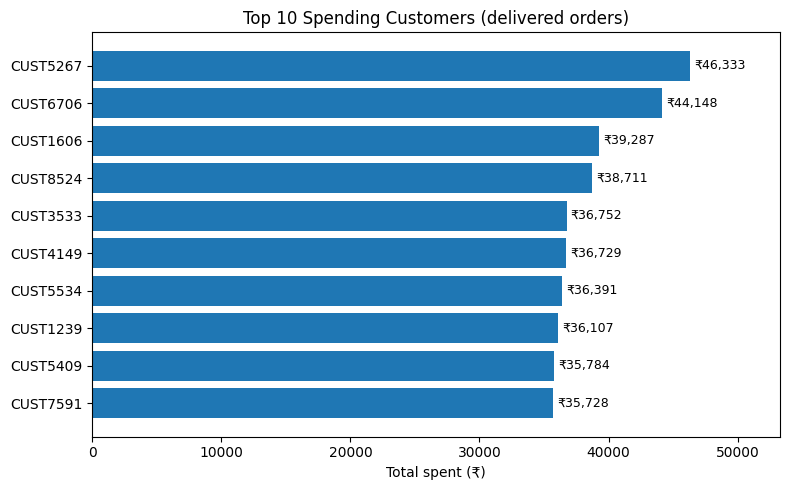

In [ ]:
import matplotlib.pyplot as plt

top10 = customer_spend.head(10).sort_values("total_spent")   # sorted so the biggest bar is on top

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top10["Customer_ID"], top10["total_spent"])
ax.bar_label(bars, labels=[f"₹{v:,.0f}" for v in top10["total_spent"]], padding=3, fontsize=9)
ax.set_title("Top 10 Spending Customers (delivered orders)")
ax.set_xlabel("Total spent (₹)")
ax.set_xlim(0, top10["total_spent"].max() * 1.15)    # leaves room for the labels
plt.tight_layout()
plt.show()

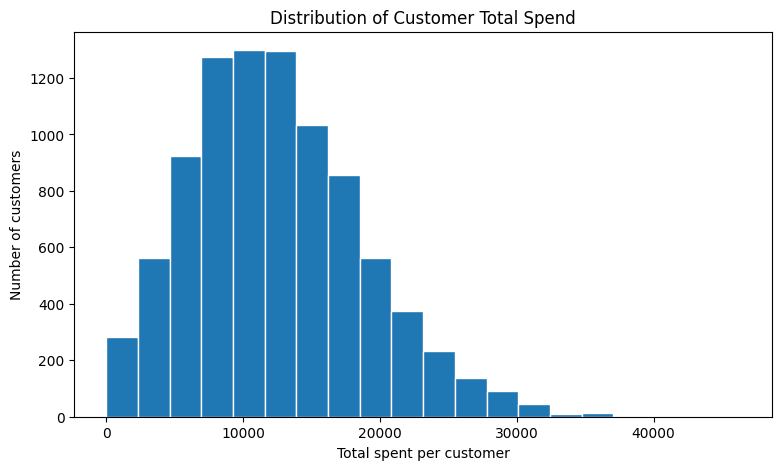

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(customer_spend["total_spent"], bins=20, edgecolor="white")


ax.set_title("Distribution of Customer Total Spend")
ax.set_xlabel("Total spent per customer")
ax.set_ylabel("Number of customers")
plt.show()

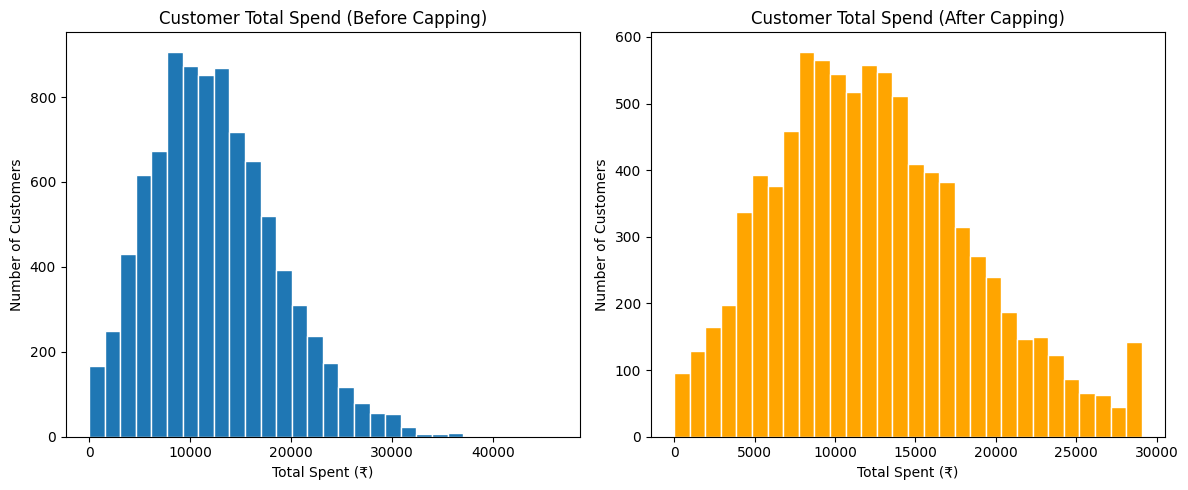

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate customer spending from the delivered orders
delivered = df[df["Order_Status"] != "Cancelled"]
customer_spend = (
    delivered.groupby("Customer_ID")["Final_Amount"]
    .sum()
    .reset_index(name="total_spent")
)

# Create a capped version of customer spending using 1.5 * IQR
q1, q3 = customer_spend["total_spent"].quantile([0.25, 0.75])
iqr = q3 - q1
hi_fence = q3 + 1.5 * iqr

customer_spend_capped = customer_spend.copy()
customer_spend_capped["total_spent"] = customer_spend_capped["total_spent"].clip(upper=hi_fence)

# Plot the comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(customer_spend["total_spent"], bins=30, edgecolor="white")
plt.title("Customer Total Spend (Before Capping)")
plt.xlabel("Total Spent (₹)")
plt.ylabel("Number of Customers")

plt.subplot(1, 2, 2)
plt.hist(customer_spend_capped["total_spent"], bins=30, edgecolor="white", color="orange")
plt.title("Customer Total Spend (After Capping)")
plt.xlabel("Total Spent (₹)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Analyze age group vs order value



In [ ]:
import pandas as pd

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
ad = raw.dropna(subset=["Customer_Age", "Order_Value"]).copy()     # real values only

bins = [17, 24, 34, 44, 54, 100]
labels = ["18-24", "25-34", "35-44", "45-54", "55+"]
ad["Age_Group"] = pd.cut(ad["Customer_Age"], bins=bins, labels=labels)

age_summary = ad.groupby("Age_Group", observed=True)["Order_Value"].agg(
    orders="count", mean="mean", median="median", std="std"
).round(1)
display(age_summary)

print("Correlation:", round(ad[["Customer_Age", "Order_Value"]].corr().iloc[0, 1], 4))




,orders,mean,median,std
Age_Group,,,,
18-24,5420,2078.4,2005.0,1542.1
25-34,7837,2098.7,2014.0,1556.1
35-44,7732,2052.4,1179.5,1536.7
45-54,7792,2106.3,2046.5,1553.3
55+,4589,2035.1,1175.0,1546.8


Correlation: -0.0029


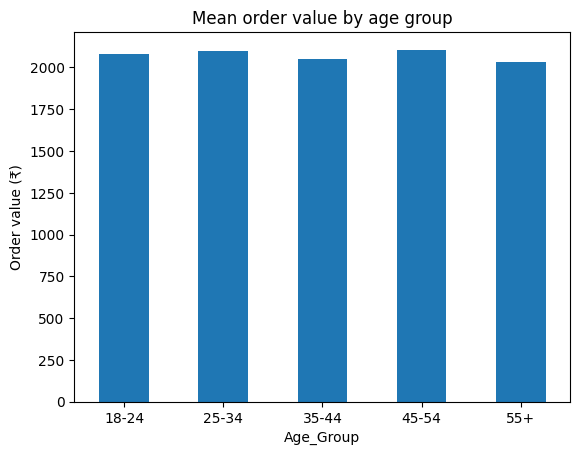

In [ ]:
age_summary["mean"].plot(kind="bar", rot=0, title="Mean order value by age group")
plt.ylabel("Order value (₹)")
plt.show()

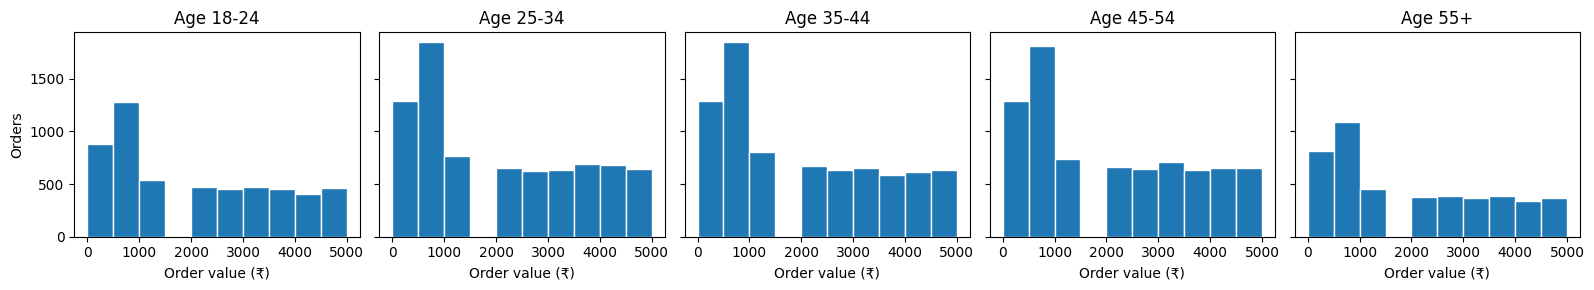

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (grp, sub) in zip(axes, ad.groupby("Age_Group", observed=True)):
    ax.hist(sub["Order_Value"], bins=10, range=(0, 5000), edgecolor="white")
    ax.set_title(f"Age {grp}")
    ax.set_xlabel("Order value (₹)")
axes[0].set_ylabel("Orders")
plt.tight_layout()
plt.show()

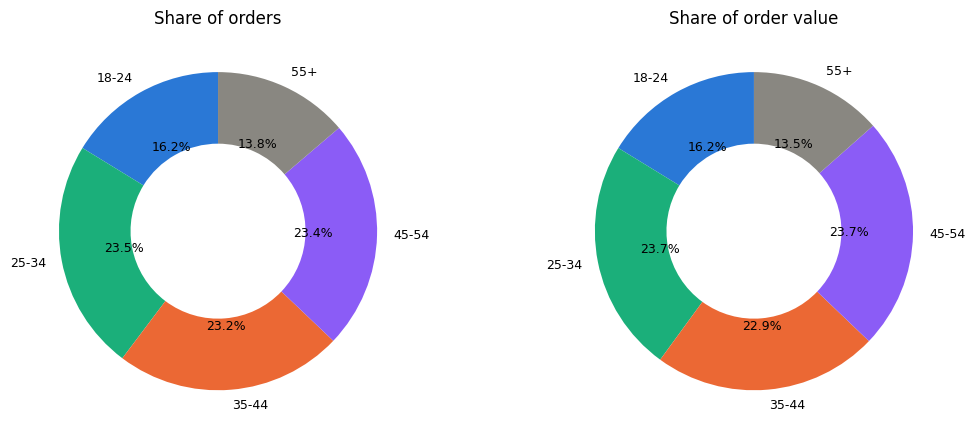

In [ ]:
import matplotlib.pyplot as plt

# Call groupby on the defined DataFrame 'ad'
summary = ad.groupby("Age_Group", observed=True)["Order_Value"].agg(orders="count", value="sum")
colors = ["#2a78d6", "#1baf7a", "#eb6834", "#8b5cf6", "#898781"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title in zip(axes, ["orders", "value"], ["Share of orders", "Share of order value"]):
    ax.pie(summary[col], labels=summary.index, autopct="%1.1f%%", startangle=90,
           colors=colors, wedgeprops=dict(width=0.45), textprops={"fontsize": 9})
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Order_Weekday', 'Order_Month', 'Delivery_Performance'],
      dtype='object')

In [ ]:
display(df["Order_Day"].value_counts())

,count
Order_Day,
Weekday,70618
Weekend,28368


Weekend vs weekday order patterns




In [ ]:
summary = df.groupby("Order_Day").agg(
    total_orders=("Order_ID", "count"),
    total_order_value=("Order_Value", "sum"),

)
display(summary)


,total_orders,total_order_value
Order_Day,,
Weekday,70618,100161383.0
Weekend,28368,39840014.0


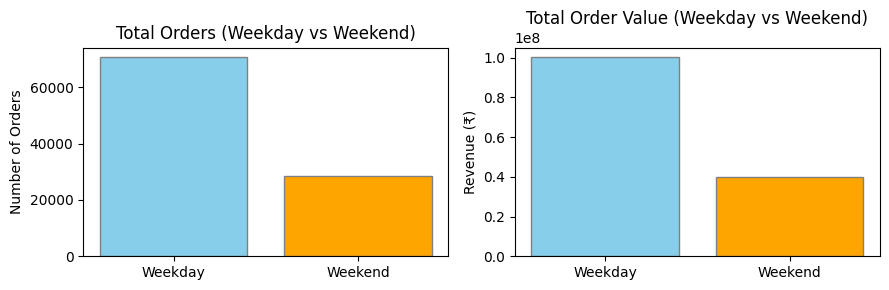

In [ ]:
import matplotlib.pyplot as plt

# Aggregate metrics by Order_Day
totals = df.groupby("Order_Day").agg(
    total_orders=("Order_ID", "count"),
    total_order_value=("Order_Value", "sum"),
)

# Create side-by-side bar plots to compare Weekday and Weekend metrics
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

# Plot 1: Total Orders
axes[0].bar(totals.index, totals["total_orders"], color=["skyblue", "orange"], edgecolor="grey")
axes[0].set_title("Total Orders (Weekday vs Weekend)")
axes[0].set_ylabel("Number of Orders")

# Plot 2: Total Order Value
axes[1].bar(totals.index, totals["total_order_value"], color=["skyblue", "orange"], edgecolor="grey")
axes[1].set_title("Total Order Value (Weekday vs Weekend)")
axes[1].set_ylabel("Revenue (₹)")

plt.tight_layout()
plt.show()

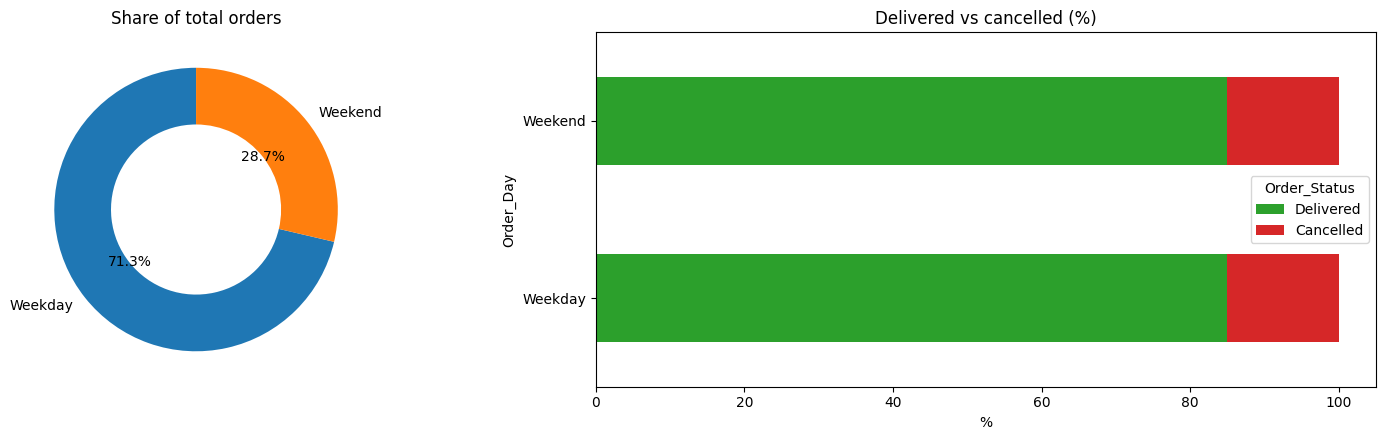

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
# 1. Donut: share of orders
counts = df["Order_Day"].value_counts().reindex(["Weekday", "Weekend"])
axes[0].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=["tab:blue", "tab:orange"], wedgeprops=dict(width=0.4))
axes[0].set_title("Share of total orders")

# 2. 100% stacked bar: delivered vs cancelled
status = pd.crosstab(df["Order_Day"], df["Order_Status"], normalize="index") * 100
status[["Delivered", "Cancelled"]].plot(kind="barh", stacked=True, ax=axes[1],
                                         color=["tab:green", "tab:red"])
axes[1].set_title("Delivered vs cancelled (%)")
axes[1].set_xlabel("%")
plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Order_Weekday', 'Order_Month', 'Delivery_Performance'],
      dtype='object')

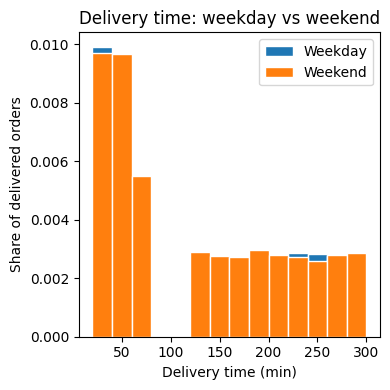

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["Order_Day"] = raw["Order_Day"].str.title()
real = raw[raw["Order_Status"].str.title() != "Cancelled"].dropna(subset=["Delivery_Time_Min"])

fig, ax = plt.subplots(figsize=(4, 4))
for day, sub in real.groupby("Order_Day"):
    ax.hist(sub["Delivery_Time_Min"], bins=np.arange(20, 320, 20),
            density=True, label=day, edgecolor="white")
ax.set_title("Delivery time: weekday vs weekend")
ax.set_xlabel("Delivery time (min)")
ax.set_ylabel("Share of delivered orders")
ax.legend()
plt.tight_layout()
plt.show()


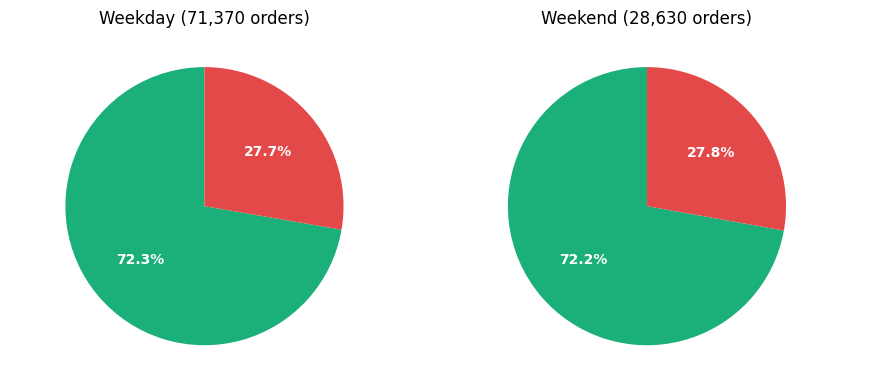

In [ ]:
import matplotlib.pyplot as plt

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["Order_Day"] = raw["Order_Day"].str.title()
raw["Result"] = np.where(raw["Profit_Margin"] < 0, "Loss-making", "Profitable")

counts = pd.crosstab(raw["Order_Day"], raw["Result"])[["Profitable", "Loss-making"]]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, day in zip(axes, ["Weekday", "Weekend"]):
    ax.pie(counts.loc[day], labels=counts.columns, autopct="%1.1f%%", startangle=90,
           colors=["#1baf7a", "#e34948"], textprops={"color": "white", "weight": "bold"})
    ax.set_title(f"{day} ({counts.loc[day].sum():,} orders)")
plt.tight_layout()
plt.show()

Monthly revenue trends




In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Order_Weekday', 'Order_Month', 'Delivery_Performance'],
      dtype='object')

In [ ]:
dated = df.dropna(subset=["Order_Date"]).copy()
delivered = dated[dated["Order_Status"] != "Cancelled"].copy()
delivered["Month"] = delivered["Order_Date"].dt.month

print("Delivered orders with a date:", len(delivered))
print("Total revenue (millions):", round(delivered["Final_Amount"].sum() / 1e6, 2))
monthly = delivered.groupby("Month").agg(
    revenue=("Final_Amount", "sum"),
    orders=("Order_ID", "count"),
    avg_order_value=("Final_Amount", "mean"),
)
monthly["revenue_per_month"] = (monthly["revenue"] / 1e6).round(2)
monthly["revenue_per_day_K"] = (monthly["revenue"] / days_in_month / 1e3).round(1)
monthly["avg_order_value"] = monthly["avg_order_value"].round(0)
monthly.index = pd.to_datetime(monthly.index, format="%m").strftime("%b")

display(monthly[["revenue_per_month", "orders", "avg_order_value", "revenue_per_day_K"]])

Delivered orders with a date: 84100
Total revenue (millions): 111.78


,revenue_per_month,orders,avg_order_value,revenue_per_day_K
Month,,,,
Jan,9.60,7179,1338.0,309.8
Feb,8.92,6748,1322.0,307.6
Mar,9.40,7138,1317.0,303.3
Apr,9.13,6886,1326.0,304.3
May,9.53,7124,1337.0,307.3
Jun,9.20,6907,1332.0,306.6
Jul,9.77,7244,1348.0,315.0
Aug,9.37,7039,1331.0,302.2
Sep,9.45,6972,1356.0,315.2


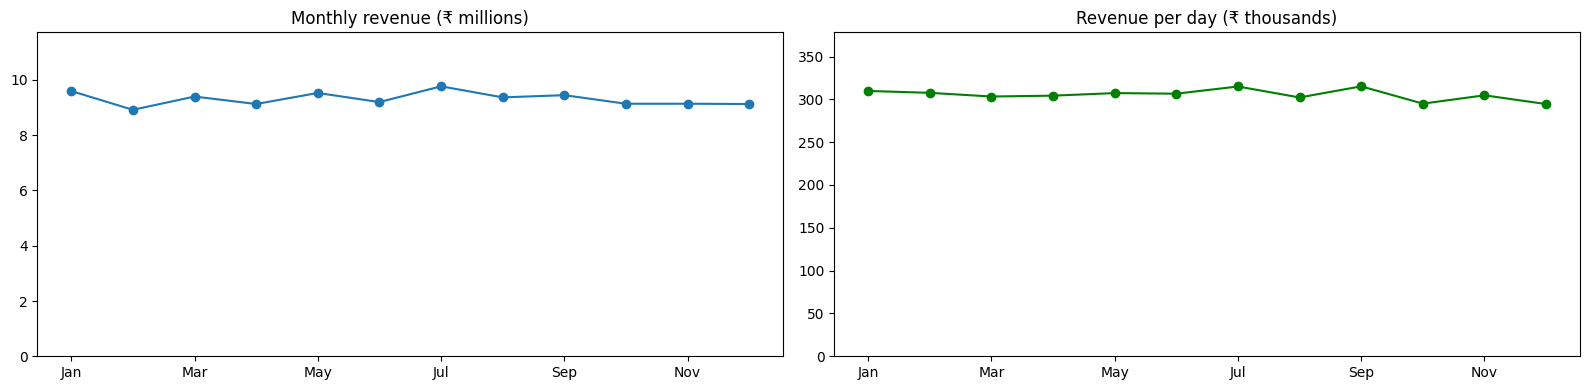

In [ ]:
import matplotlib.pyplot as plt

# Calculate Month-over-Month change percent since it was missing
monthly["mom_change_%"] = monthly["revenue_per_month"].pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# 1. Corrected 'revenue_M' to 'revenue_per_month'
monthly["revenue_per_month"].plot(ax=axes[0], marker="o", title="Monthly revenue (₹ millions)")
axes[0].set_ylim(0, monthly["revenue_per_month"].max() * 1.2)
axes[0].set_xlabel("")

# 2. Revenue per day
monthly["revenue_per_day_K"].plot(ax=axes[1], marker="o", color="green",
                                  title="Revenue per day (₹ thousands)")
axes[1].set_ylim(0, monthly["revenue_per_day_K"].max() * 1.2)
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()


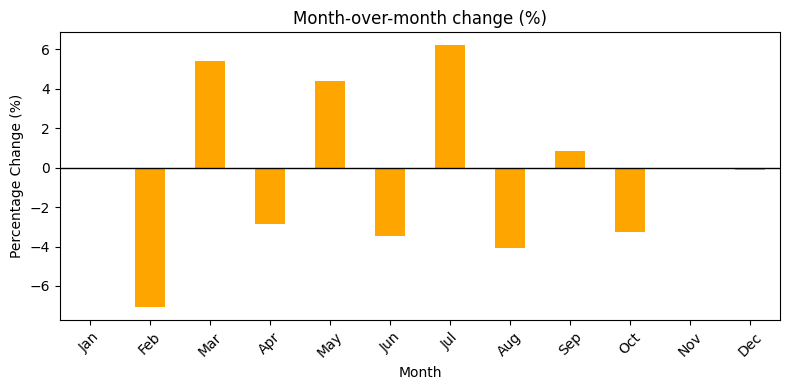

In [ ]:
import matplotlib.pyplot as plt

# Create a separate, new figure for the Month-over-Month plot
fig, ax = plt.subplots(figsize=(8, 4))

monthly["mom_change_%"].fillna(0).plot(kind="bar", ax=ax, title="Month-over-month change (%)", rot=45, color="orange")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Month")
ax.set_ylabel("Percentage Change (%)")

plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status',
       'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating',
       'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin',
       'Order_Weekday', 'Order_Month', 'Delivery_Performance'],
      dtype='object')

/tmp/ipykernel_3468/3689521550.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


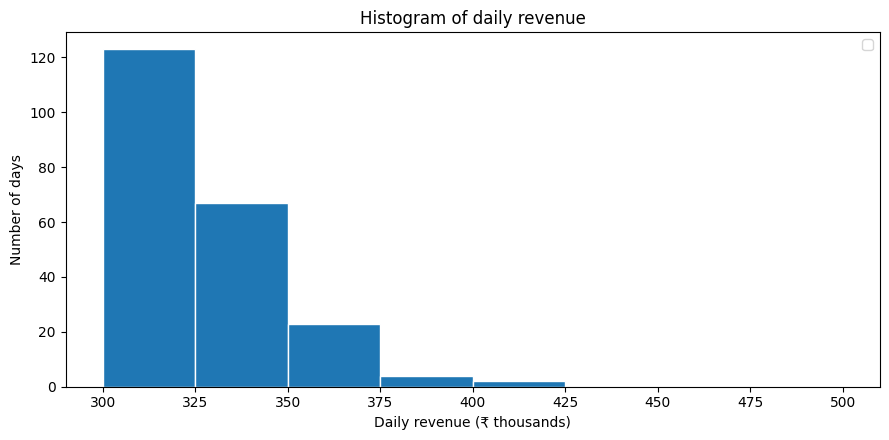

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

daily = delivered.groupby("Order_Date")["Final_Amount"].sum() / 1e3

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(daily, bins=np.arange(300, 525, 25), edgecolor="white")
ax.set_title("Histogram of daily revenue")
ax.set_xlabel("Daily revenue (₹ thousands)")
ax.set_ylabel("Number of days")
ax.legend()
plt.tight_layout()
plt.show()


Impact of discounts on profit




In [ ]:
raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
d = raw.dropna(subset=["Discount_Applied"]).copy()          # original discounts only

summary = d.groupby("Discount_Applied").agg(
    orders=("Order_ID", "count"),
    avg_margin=("Profit_Margin", lambda s: s.mean() * 100),
    loss_share=("Profit_Margin", lambda s: (s < 0).mean() * 100),
    avg_order_value=("Order_Value", "mean"),
).round(1)
display(summary)

,orders,avg_margin,loss_share,avg_order_value
Discount_Applied,,,,
0.0,16650,15.1,27.7,2062.5
20.0,16569,14.9,27.9,2068.2
50.0,16690,14.9,28.1,2077.8
100.0,16776,15.1,27.8,2083.3
300.0,16600,15.3,27.2,2084.9


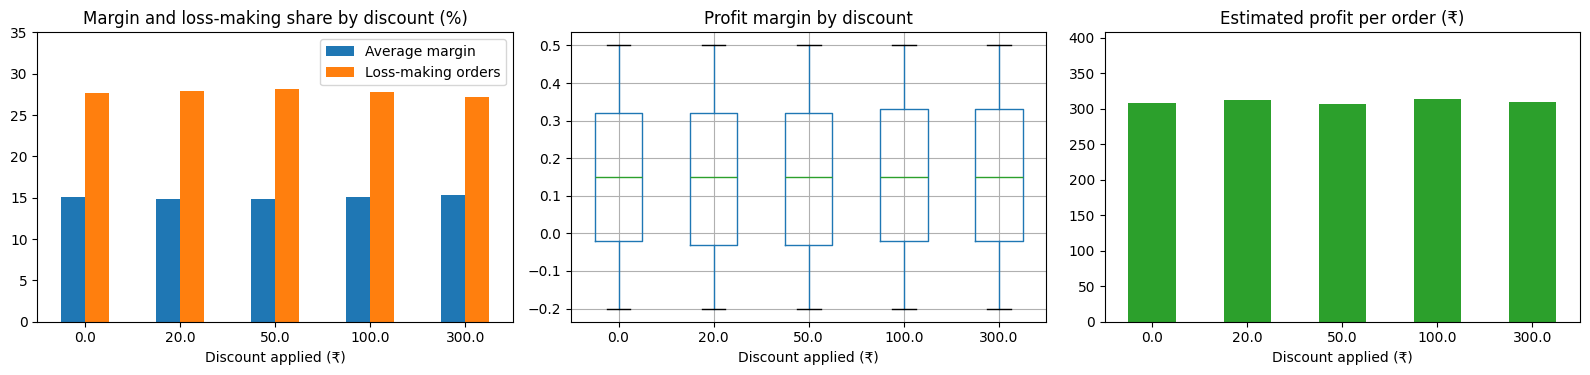

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Corrected the column names from 'avg_margin_pct'/'loss_share_pct' to 'avg_margin'/'loss_share'
summary[["avg_margin", "loss_share"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Margin and loss-making share by discount (%)")
axes[0].set_xlabel("Discount applied (₹)")
axes[0].set_ylim(0, 35)
axes[0].legend(["Average margin", "Loss-making orders"])

d.boxplot(column="Profit_Margin", by="Discount_Applied", ax=axes[1])
axes[1].set_title("Profit margin by discount")
axes[1].set_xlabel("Discount applied (₹)")

profit_by_discount["avg_profit_per_order"].plot(kind="bar", ax=axes[2], rot=0, color="tab:green")
axes[2].set_title("Estimated profit per order (₹)")
axes[2].set_xlabel("Discount applied (₹)")
axes[2].set_ylim(0, profit_by_discount["avg_profit_per_order"].max() * 1.3)

plt.suptitle("")
plt.tight_layout()
plt.show()

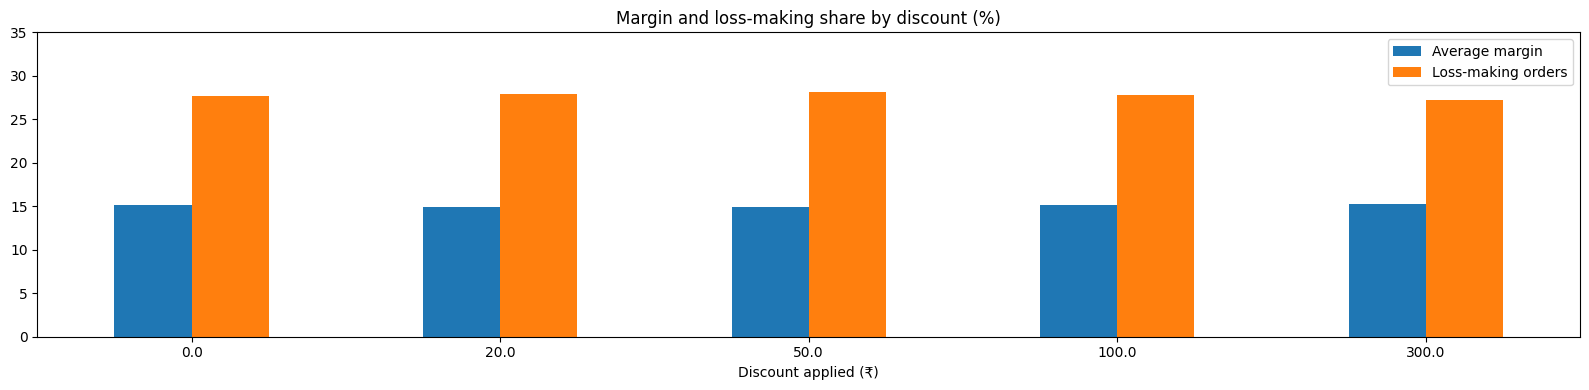

In [ ]:
fig, ax = plt.subplots(figsize=(16, 4))

# Corrected the column names and used the single 'ax' object directly
summary[["avg_margin", "loss_share"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Margin and loss-making share by discount (%)")
ax.set_xlabel("Discount applied (₹)")
ax.set_ylim(0, 35)
ax.legend(["Average margin", "Loss-making orders"])
plt.tight_layout()
plt.show()

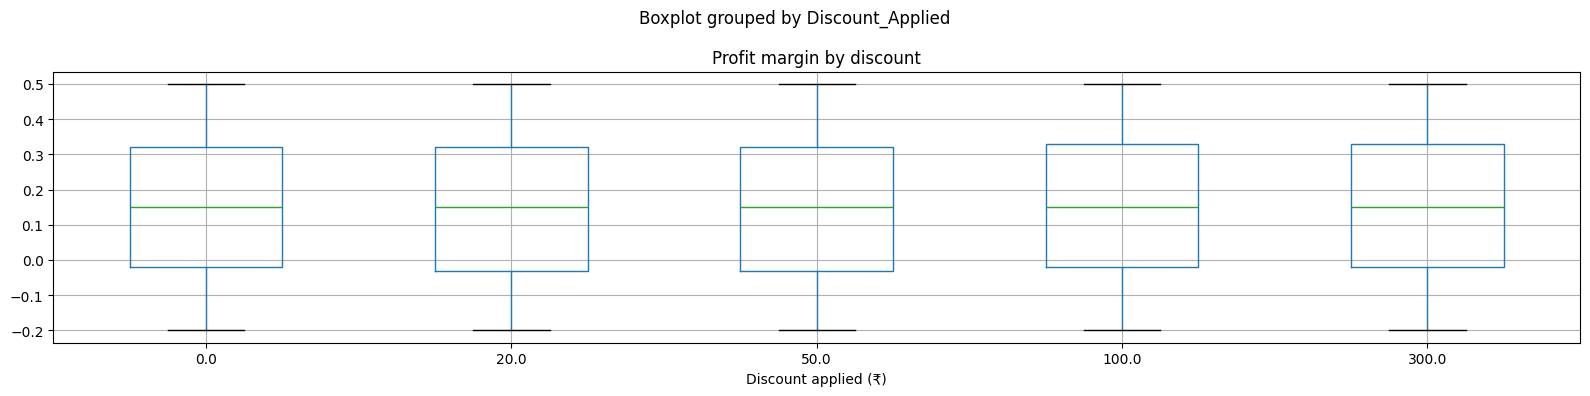

In [ ]:
fig, ax = plt.subplots(figsize=(16, 4))

d.boxplot(column="Profit_Margin", by="Discount_Applied", ax=ax)
ax.set_title("Profit margin by discount")
ax.set_xlabel("Discount applied (₹)")
plt.tight_layout()
plt.show()

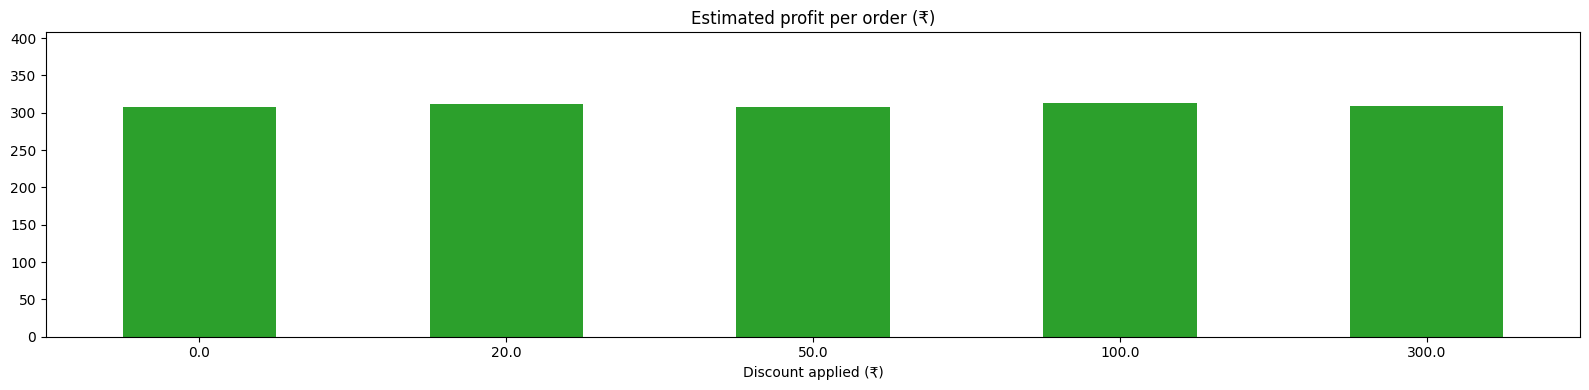

In [ ]:
fig, ax = plt.subplots(figsize=(16, 4))

profit_by_discount["avg_profit_per_order"].plot(kind="bar", ax=ax, rot=0, color="tab:green")
ax.set_title("Estimated profit per order (₹)")
ax.set_xlabel("Discount applied (₹)")
ax.set_ylim(0, profit_by_discount["avg_profit_per_order"].max() * 1.3)

plt.tight_layout()
plt.show()

In [ ]:
for col in ["City", "Cuisine_Type"]:
    t = delivered.groupby(col).agg(revenue_M=("Final_Amount", lambda s: s.sum() / 1e6),
                                   orders=("Order_ID", "count"),
                                   avg_order=("Final_Amount", "mean")).round(2)
    display(t.sort_values("revenue_M", ascending=False))

combo = known.pivot_table(index="City", columns="Cuisine_Type", values="Final_Amount", aggfunc="sum") / 1e6
display(combo.round(2))
display(combo.stack().sort_values(ascending=False).head(5))

,revenue_M,orders,avg_order
City,,,
Bangalore,18.98,14096,1346.61
Unknown,18.81,14061,1337.62
Hyderabad,18.67,14179,1316.54
Delhi,18.48,14029,1317.20
Chennai,18.43,13854,1330.55
Mumbai,18.41,13881,1326.50


,revenue_M,orders,avg_order
Cuisine_Type,,,
Unknown,19.04,14191,1342.04
Chinese,18.85,14032,1343.32
Mexican,18.77,13926,1347.66
Indian,18.70,13990,1336.38
Arabian,18.25,14039,1300.18
Italian,18.17,13922,1305.27


Cuisine_Type,Arabian,Chinese,Indian,Italian,Mexican
City,,,,,
Bangalore,3.06,3.23,3.34,3.05,3.30
Chennai,2.95,3.17,3.09,2.98,3.07
Delhi,2.97,3.22,3.12,2.98,3.09
Hyderabad,3.05,2.98,3.12,3.02,3.16
Mumbai,3.03,3.09,3.02,3.02,3.00


City       Cuisine_Type
Bangalore  Indian          3.336635
           Mexican         3.302899
           Chinese         3.227529
Delhi      Chinese         3.218566
Chennai    Chinese         3.168984
dtype: float64

In [ ]:
df["City"]

,City
0,Unknown
1,Chennai
2,Delhi
3,Mumbai
4,Chennai
...,...
99994,Delhi
99995,Mumbai
99996,Mumbai
99997,Delhi


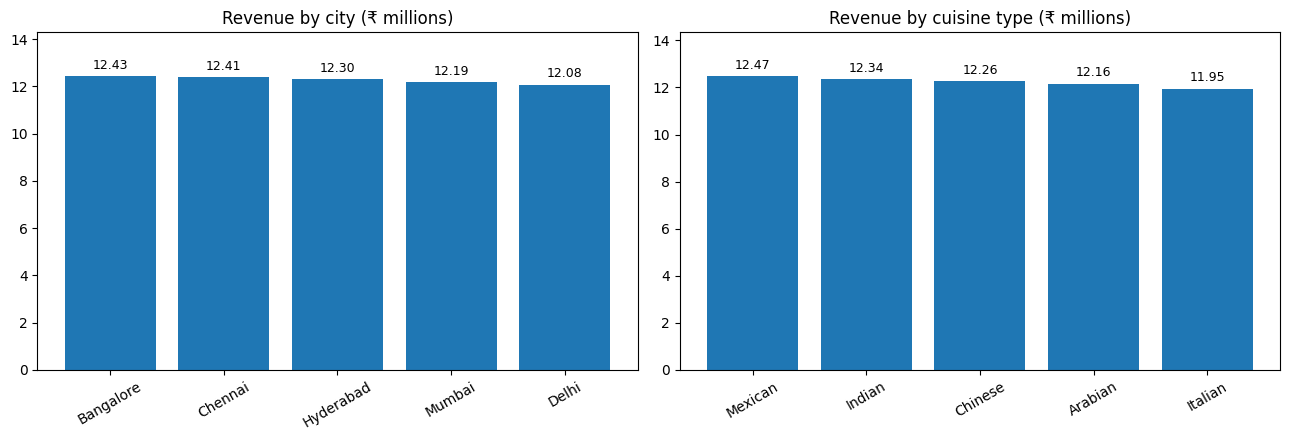

In [ ]:
import matplotlib.pyplot as plt

delivered = df[df["Order_Status"] != "Cancelled"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["City", "Cuisine_Type"]):
    known = delivered[delivered[col] != "Unknown"]
    rev = (known.groupby(col)["Final_Amount"].sum() / 1e6).sort_values(ascending=False)
    bars = ax.bar(rev.index, rev.values)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    ax.set_ylim(0, rev.max() * 1.15)
    ax.set_title(f"Revenue by {col.replace('_', ' ').lower()} (₹ millions)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

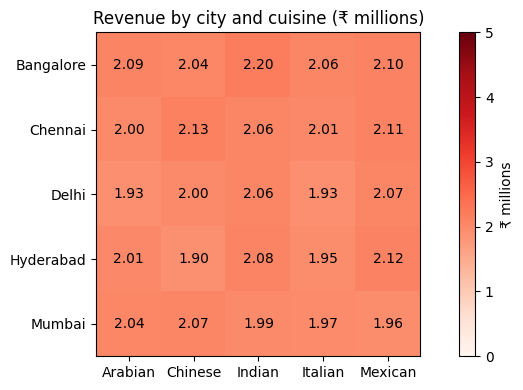

In [ ]:
import matplotlib.pyplot as plt

delivered = df[df["Order_Status"] != "Cancelled"]
known = delivered[(delivered["City"] != "Unknown") & (delivered["Cuisine_Type"] != "Unknown")]
heat = known.pivot_table(index="City", columns="Cuisine_Type", values="Final_Amount", aggfunc="sum") / 1e6

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(heat, cmap="Reds", vmin=0, vmax=5)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > 2.5 else "black")
ax.set_title("Revenue by city and cuisine (₹ millions)")
plt.colorbar(im, label="₹ millions")
plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km',
       'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Delivery_Rating', 'Restaurant_Rating', 'Order_Day', 'Peak_Hour',
       'Profit_Margin'],
      dtype='object')

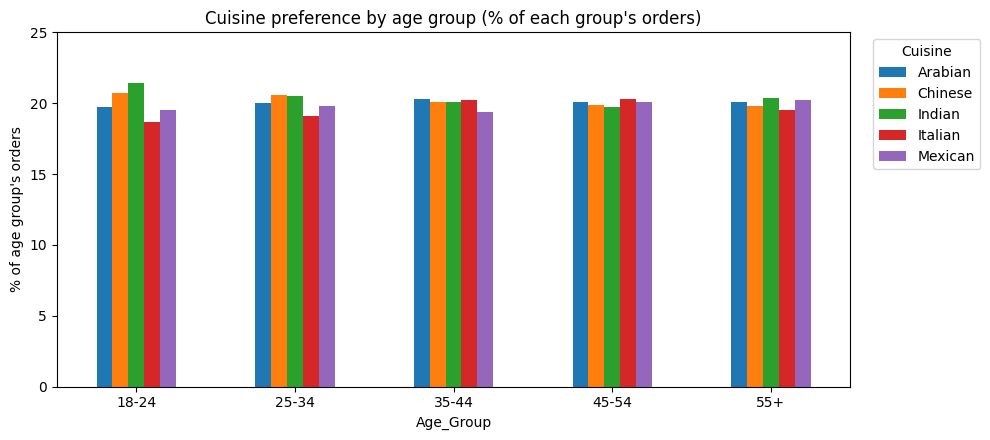

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
d = raw.dropna(subset=["Customer_Age", "Cuisine_Type"]).copy()      # real values only

bins = [17, 24, 34, 44, 54, 100]
labels = ["18-24", "25-34", "35-44", "45-54", "55+"]
d["Age_Group"] = pd.cut(d["Customer_Age"], bins=bins, labels=labels)

counts = pd.crosstab(d["Age_Group"], d["Cuisine_Type"])
share = (pd.crosstab(d["Age_Group"], d["Cuisine_Type"], normalize="index") * 100).round(1)
chi2, p, _, _ = stats.chi2_contingency(counts)
share.plot(kind="bar", rot=0, figsize=(10, 4.5))
plt.ylim(0, 25)
plt.title("Cuisine preference by age group (% of each group's orders)")
plt.ylabel("% of age group's orders")
plt.legend(title="Cuisine", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Average delivery time by city




In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["City"] = raw["City"].str.strip().str.title()
d = raw[raw["Order_Status"].str.title() == "Delivered"].dropna(subset=["City", "Delivery_Time_Min"])

city_time = d.groupby("City")["Delivery_Time_Min"].agg(orders="count", avg="mean", median="median").round(1)
display(city_time.sort_values("avg"))



,orders,avg,median
City,,,
Bangalore,9526,126.5,70.0
Chennai,9392,126.5,70.0
Delhi,9403,127.6,121.0
Hyderabad,9557,127.8,120.0
Mumbai,9393,128.6,122.0


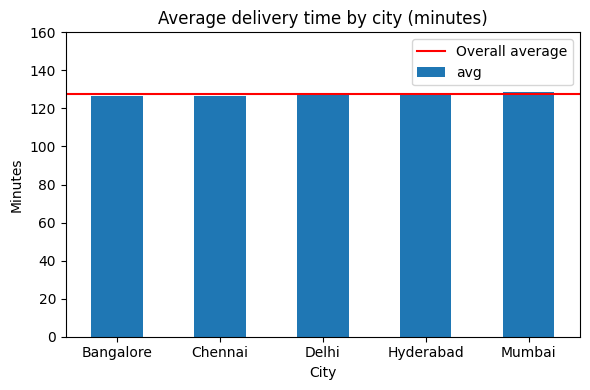

In [ ]:
ax = city_time["avg"].sort_values().plot(kind="bar", rot=0, figsize=(6, 4))

ax.axhline(d["Delivery_Time_Min"].mean(), color="red", linestyle="-", label="Overall average")
ax.set_ylim(0, 160)
ax.set_title("Average delivery time by city (minutes)")
ax.set_ylabel("Minutes")
ax.legend()
plt.tight_layout()
plt.show()

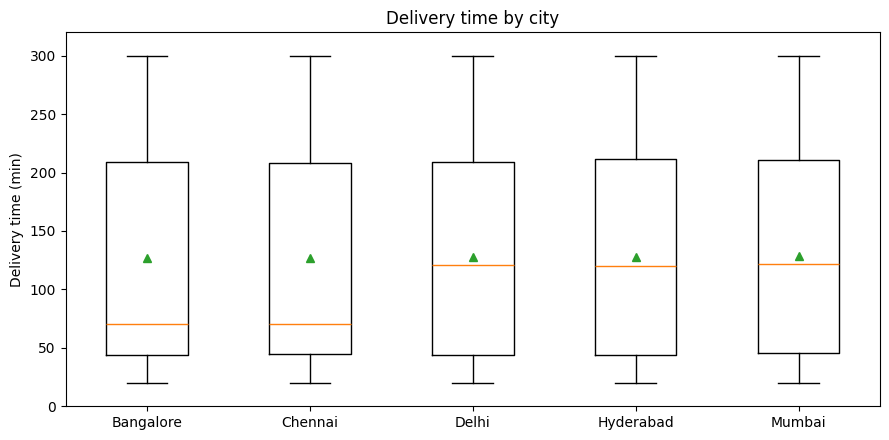

In [ ]:
import matplotlib.pyplot as plt

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["City"] = raw["City"].str.strip().str.title()
d = raw[raw["Order_Status"].str.title() == "Delivered"].dropna(subset=["City", "Delivery_Time_Min"])

cities = sorted(d["City"].unique())
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([d.loc[d["City"] == c, "Delivery_Time_Min"] for c in cities],
           tick_labels=cities, showmeans=True, whis=(0, 100))
ax.set_ylim(0, 320)
ax.set_ylabel("Delivery time (min)")
ax.set_title("Delivery time by city")
plt.tight_layout()
plt.show()

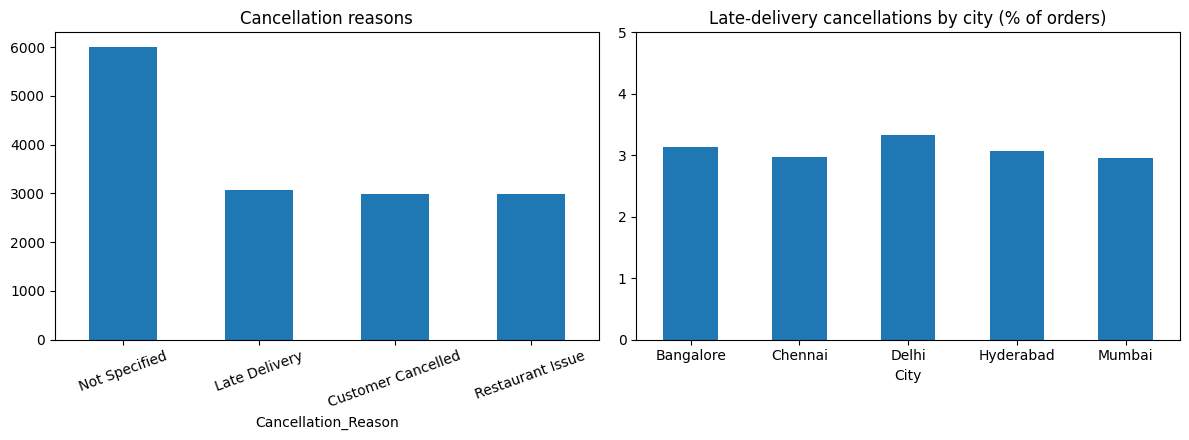

In [ ]:


# Charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cancelled["Cancellation_Reason"].fillna("Not Specified").value_counts().plot(kind="bar", ax=axes[0], rot=20)
axes[0].set_title("Cancellation reasons")
(raw.dropna(subset=["City"]).groupby("City")["Late_Cancel"].mean() * 100).plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_ylim(0, 5)
axes[1].set_title("Late-delivery cancellations by city (% of orders)")
plt.tight_layout()
plt.show()

Distance vs delivery delay analysis




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
d = raw[raw["Order_Status"].str.title() == "Delivered"].dropna(subset=["Distance_km", "Delivery_Time_Min"]).copy()

DELAY_MINUTES = 150                       # change to whatever you define as "delayed"
d["Delayed"] = d["Delivery_Time_Min"] > DELAY_MINUTES
d["Distance_Band"] = pd.cut(d["Distance_km"], [0, 5, 10, 15, 20, 30, 40])
bands = d.groupby("Distance_Band", observed=True).agg(
    orders=("Distance_km", "size"),
    avg_min=("Delivery_Time_Min", "mean"),
    delayed=("Delayed", lambda s: s.mean() * 100),
).round(1)
display(bands)



,orders,avg_min,delayed
Distance_Band,,,
"(0, 5]",8434,126.2,40.5
"(5, 10]",10447,127.0,41.1
"(10, 15]",7,140.0,42.9
"(15, 20]",3805,128.5,41.9
"(20, 30]",7603,128.9,42.1
"(30, 40]",7490,127.7,41.8


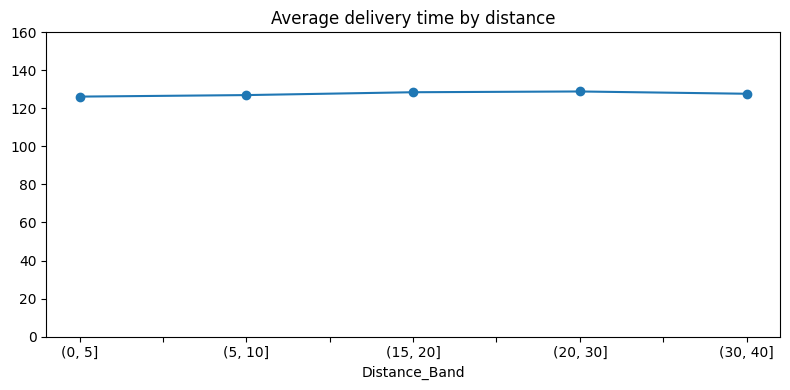

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
reliable = bands[bands["orders"] > 100]          # skip the 7-order band
reliable["avg_min"].plot(ax=ax, marker="o", title="Average delivery time by distance")
ax.set_ylim(0, 160)

plt.tight_layout()
plt.show()

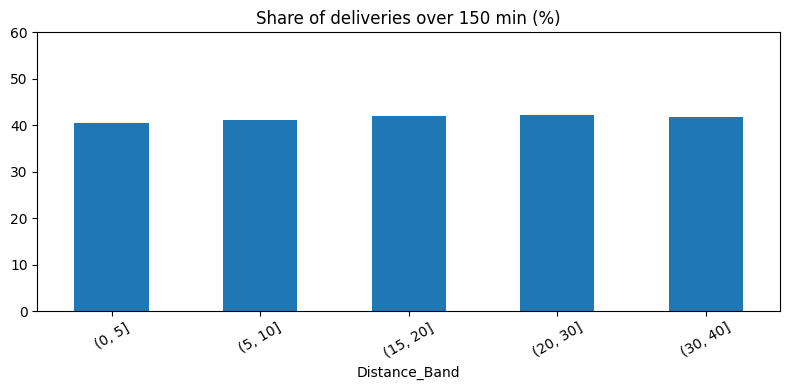

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
reliable = bands[bands["orders"] > 100]          # skip the 7-order band

reliable["delayed"].plot(kind="bar", ax=ax, rot=30, title=f"Share of deliveries over {DELAY_MINUTES} min (%)")
ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()

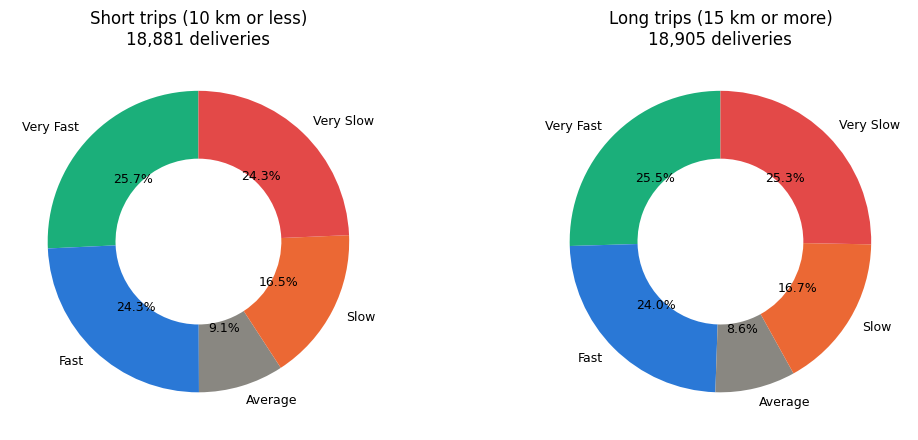

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

labels = ["Very Fast", "Fast", "Average", "Slow", "Very Slow"]
colors = ["#1baf7a", "#2a78d6", "#898781", "#eb6834", "#e34948"]
d["Speed"] = pd.cut(d["Delivery_Time_Min"], [0, 45, 90, 150, 210, np.inf], labels=labels)

groups = {"Short trips (10 km or less)": d[d["Distance_km"] <= 10],
          "Long trips (15 km or more)": d[d["Distance_km"] >= 15]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, sub) in zip(axes, groups.items()):
    counts = sub["Speed"].value_counts().reindex(labels)
    ax.pie(counts, labels=labels, colors=colors, autopct="%1.1f%%", startangle=90,
           wedgeprops=dict(width=0.45), textprops={"fontsize": 9})
    ax.set_title(f"{title}\n{len(sub):,} deliveries")
plt.tight_layout()
plt.show()

Delivery rating vs delivery time

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
d = raw[raw["Order_Status"].str.title() == "Delivered"].dropna(subset=["Delivery_Rating", "Delivery_Time_Min"]).copy()
labels = ["Very Fast", "Fast", "Average", "Slow", "Very Slow"]
d["Speed"] = pd.cut(d["Delivery_Time_Min"], [0, 45, 90, 150, 210, np.inf], labels=labels)

summary = d.groupby("Speed", observed=True)["Delivery_Rating"].agg(
    deliveries="count", avg_rating="mean"
).round(2)
display(summary)

,deliveries,avg_rating
Speed,,
Very Fast,12024,2.98
Fast,11469,3.00
Average,4152,2.99
Slow,7825,2.99
Very Slow,11731,3.01


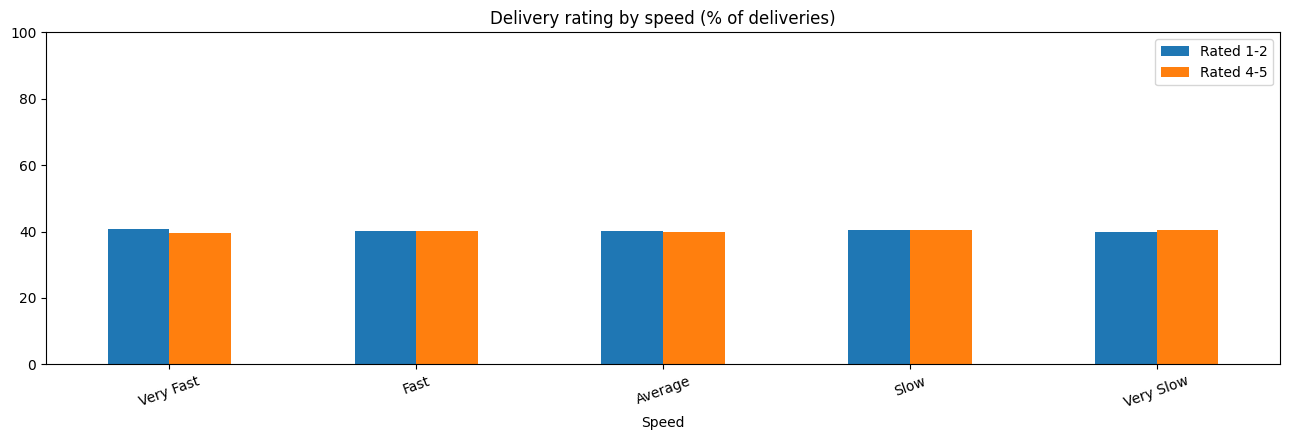

In [ ]:
# Calculate the low (1-2) and high (4-5) rating percentages
summary["low_pct"] = d.groupby("Speed", observed=True)["Delivery_Rating"].apply(lambda s: (s <= 2).mean() * 100).round(1)
summary["high_pct"] = d.groupby("Speed", observed=True)["Delivery_Rating"].apply(lambda s: (s >= 4).mean() * 100).round(1)

# Fix the variable mismatch (use 'ax' in both subplots and plotting)
fig, ax = plt.subplots(figsize=(13, 4.5))
summary[["low_pct", "high_pct"]].plot(kind="bar", ax=ax, rot=20)
ax.set_ylim(0, 100)
ax.set_title("Delivery rating by speed (% of deliveries)")
ax.legend(["Rated 1-2", "Rated 4-5"])
plt.tight_layout()
plt.show()

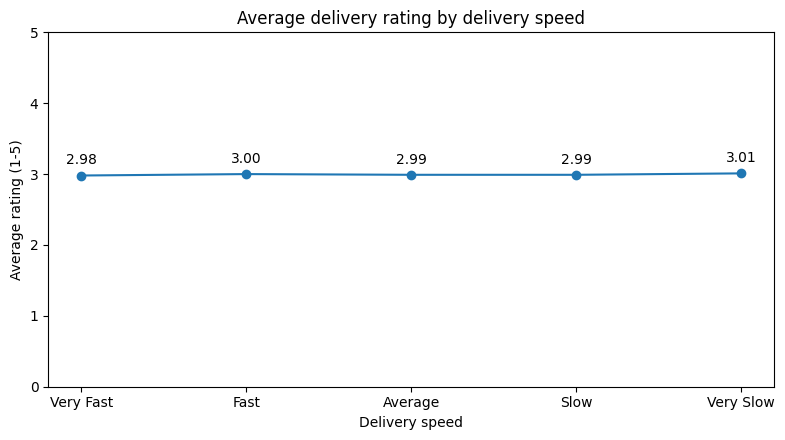

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(summary.index.astype(str), summary["avg_rating"], marker="o", color="tab:blue")
for x, y in zip(summary.index.astype(str), summary["avg_rating"]):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylim(0, 5)
ax.set_xlabel("Delivery speed")
ax.set_ylabel("Average rating (1-5)")
ax.set_title("Average delivery rating by delivery speed")
plt.tight_layout()
plt.show()

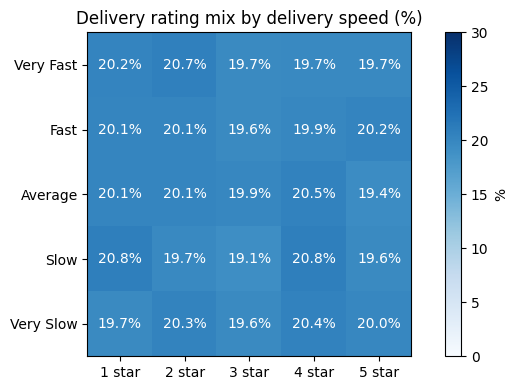

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Safely initialize 'd' from the existing cleaned 'df'
# Filtering for delivered orders and dropping rows missing delivery ratings or delivery times
d = df[(df["Order_Status"] != "Cancelled")].dropna(subset=["Delivery_Time_Min", "Delivery_Rating"]).copy()

d["Speed"] = pd.cut(d["Delivery_Time_Min"], [0, 45, 90, 150, 210, np.inf],
                    labels=["Very Fast", "Fast", "Average", "Slow", "Very Slow"])
share = pd.crosstab(d["Speed"], d["Delivery_Rating"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(share, cmap="Blues", vmin=0, vmax=30)
ax.set_xticks(range(5), [f"{int(r)} star" for r in share.columns])
ax.set_yticks(range(5), share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iloc[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", color="white" if v > 17 else "black")
ax.set_title("Delivery rating mix by delivery speed (%)")
plt.colorbar(im, label="%")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")

rest = raw.groupby("Restaurant_Name").agg(
    orders=("Order_ID", "count"),
    avg_rating=("Restaurant_Rating", "mean"),
    cancel_rate=("Order_Status", lambda s: (s.str.title() == "Cancelled").mean() * 100),
).round(3)
top10 = rest[rest["orders"] >= 100].sort_values("avg_rating", ascending=False).head(10)
display(top10)



,orders,avg_rating,cancel_rate
Restaurant_Name,,,
Restaurant_496,203,4.386,16.749
Restaurant_101,178,4.384,15.730
Restaurant_162,182,4.379,7.143
Restaurant_355,181,4.372,18.232
Restaurant_1,193,4.369,14.508
Restaurant_481,190,4.363,12.632
Restaurant_352,194,4.355,13.402
Restaurant_392,183,4.355,15.301
Restaurant_209,212,4.354,17.453


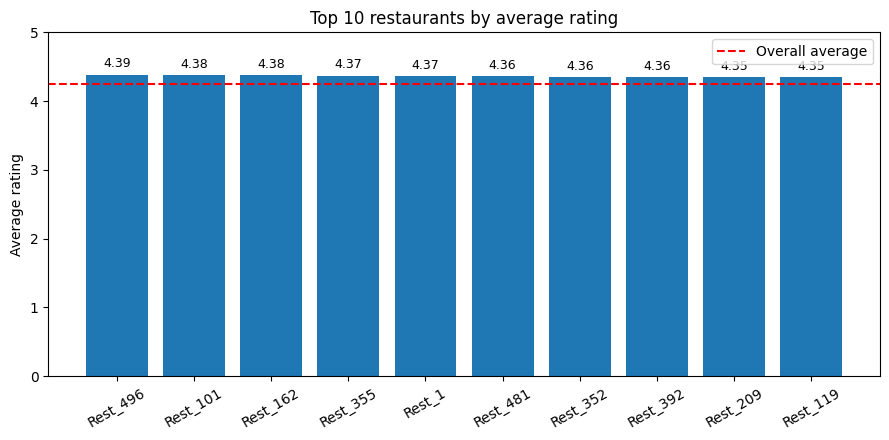

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(top10.index.str.replace("Restaurant_", "Rest_"), top10["avg_rating"])
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.axhline(raw["Restaurant_Rating"].mean(), color="red", linestyle="--", label="Overall average")
ax.set_ylim(0, 5)
ax.set_ylabel("Average rating")
ax.set_title("Top 10 restaurants by average rating")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

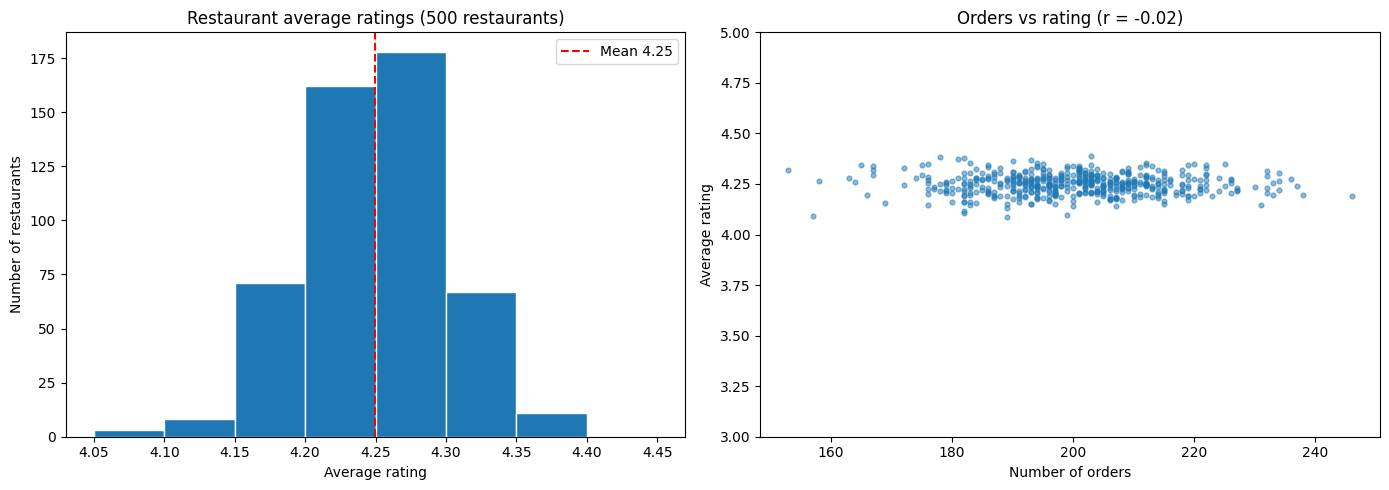

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create 1 row, 2 columns of subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram of restaurant average ratings on axes[0]
axes[0].hist(rest["avg_rating"], bins=np.arange(4.05, 4.45, 0.05), edgecolor="white")
axes[0].axvline(rest["avg_rating"].mean(), color="red", linestyle="--",
                label=f"Mean {rest['avg_rating'].mean():.2f}")
axes[0].set_title("Restaurant average ratings (500 restaurants)")
axes[0].set_xlabel("Average rating")
axes[0].set_ylabel("Number of restaurants")
axes[0].legend()

# 2. Scatter: number of orders vs average rating on axes[1]
axes[1].scatter(rest["orders"], rest["avg_rating"], s=12, alpha=0.5, color="tab:blue")
axes[1].set_title(f"Orders vs rating (r = {rest['orders'].corr(rest['avg_rating']):.2f})")
axes[1].set_xlabel("Number of orders")
axes[1].set_ylabel("Average rating")
axes[1].set_ylim(3, 5)

plt.tight_layout()
plt.show()

Cancellation rate by restaurant




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["Cancelled"] = (raw["Order_Status"].str.strip().str.title() == "Cancelled").astype(int)

rest = raw.groupby("Restaurant_Name").agg(orders=("Cancelled", "size"), cancelled=("Cancelled", "sum"))
rest["cancel_rate"] = rest["cancelled"] / rest["orders"] * 100
overall = raw["Cancelled"].mean() * 100

display(rest.sort_values("cancel_rate", ascending=False).head(10).round(1))



,orders,cancelled,cancel_rate
Restaurant_Name,,,
Restaurant_391,196,43,21.9
Restaurant_390,201,44,21.9
Restaurant_477,176,38,21.6
Restaurant_202,204,44,21.6
Restaurant_373,191,41,21.5
Restaurant_426,212,45,21.2
Restaurant_299,194,41,21.1
Restaurant_455,180,38,21.1
Restaurant_113,205,43,21.0


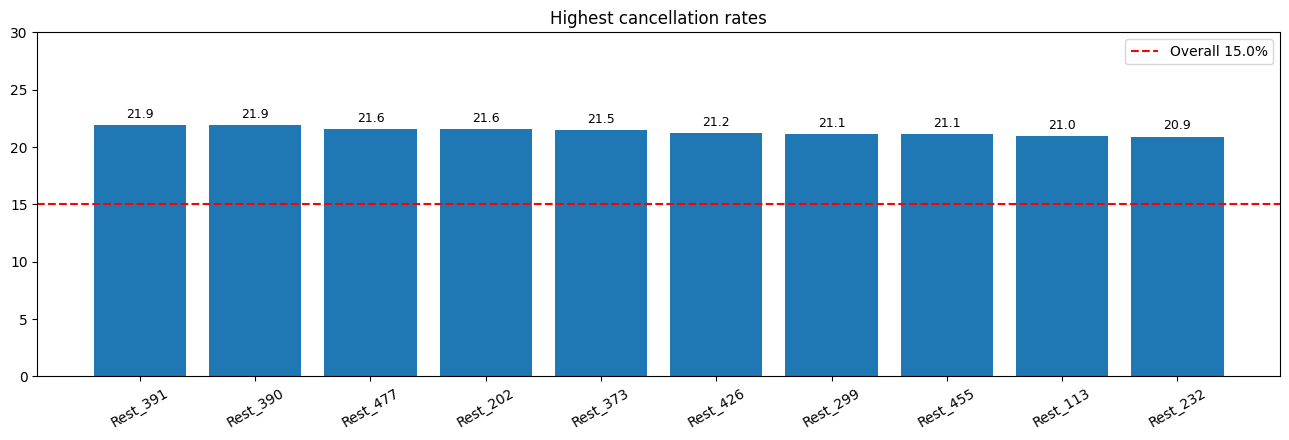

In [ ]:
fig, axes = plt.subplots(figsize=(13, 4.5))
top10 = rest.sort_values("cancel_rate", ascending=False).head(10)
bars = axes.bar(top10.index.str.replace("Restaurant_", "Rest_"), top10["cancel_rate"])
axes.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
axes.axhline(overall, color="red", linestyle="--", label=f"Overall {overall:.1f}%")
axes.set_ylim(0, 30)
axes.set_title("Highest cancellation rates")
axes.tick_params(axis="x", rotation=30)
axes.legend()
plt.tight_layout()
plt.show()


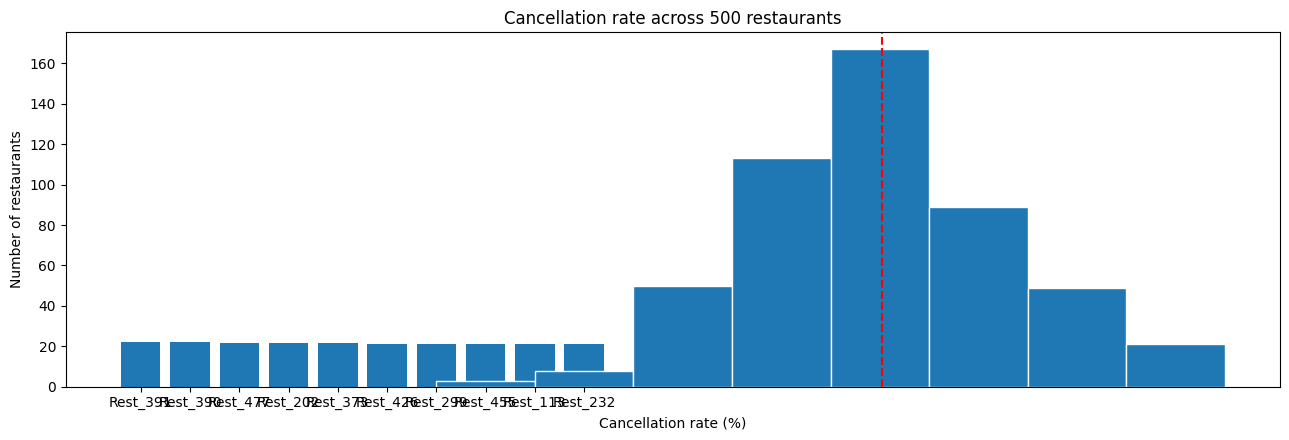

In [ ]:
fig, axes = plt.subplots(figsize=(13, 4.5))
top10 = rest.sort_values("cancel_rate", ascending=False).head(10)
bars = axes.bar(top10.index.str.replace("Restaurant_", "Rest_"), top10["cancel_rate"]),axes.hist(rest["cancel_rate"], bins=np.arange(6, 24, 2), edgecolor="white")
axes.axvline(overall, color="red", linestyle="--")
axes.set_title("Cancellation rate across 500 restaurants")
axes.set_xlabel("Cancellation rate (%)")
axes.set_ylabel("Number of restaurants")

plt.tight_layout()
plt.show()

Cuisine-wise performance




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
for c in ["Cuisine_Type", "Order_Status"]:
    raw[c] = raw[c].str.strip().str.title()
d = raw.dropna(subset=["Cuisine_Type"]).copy()
d["Cancelled"] = (d["Order_Status"] == "Cancelled").astype(int)
delivered = d[d["Order_Status"] == "Delivered"]

perf = d.groupby("Cuisine_Type").agg(
    orders=("Order_ID", "count"),
    avg_order_value=("Order_Value", "mean"),
    cancel_rate=("Cancelled", lambda s: s.mean() * 100),
    restaurant_rating=("Restaurant_Rating", "mean"),
    profit_margin=("Profit_Margin", lambda s: s.mean() * 100),
)
perf["delivery_time"] = delivered.groupby("Cuisine_Type")["Delivery_Time_Min"].mean()
perf["delivery_rating"] = delivered.groupby("Cuisine_Type")["Delivery_Rating"].mean()
perf["revenue_M"] = delivered.groupby("Cuisine_Type")["Final_Amount"].sum() / 1e6
display(perf.round(2))



,orders,avg_order_value,cancel_rate,restaurant_rating,profit_margin,delivery_time,delivery_rating,revenue_M
Cuisine_Type,,,,,,,,
Arabian,16658,2061.73,14.76,4.25,15.11,127.62,2.97,12.16
Chinese,16651,2077.83,14.88,4.24,14.93,125.60,3.01,12.26
Indian,16685,2085.33,15.42,4.25,14.92,127.99,2.99,12.34
Italian,16519,2079.56,15.08,4.26,15.16,127.92,3.01,11.95
Mexican,16602,2085.50,15.13,4.24,15.11,127.83,2.99,12.47


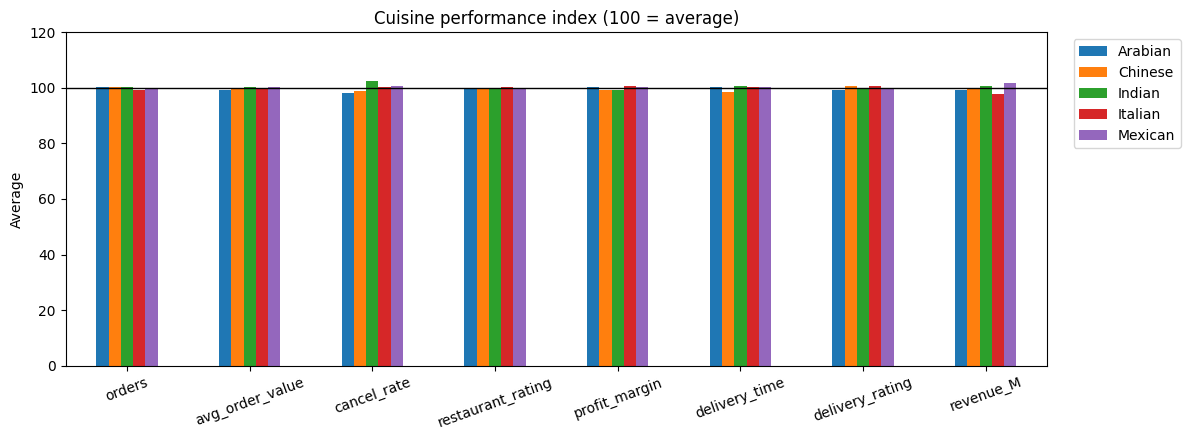

In [ ]:
# Index chart: 100 = average of the cuisines
index = (perf / perf.mean() * 100).round(1)
index.T.plot(kind="bar", figsize=(12, 4.5), rot=20)
plt.axhline(100, color="black", linewidth=1)
plt.ylim(0, 120)
plt.title("Cuisine performance index (100 = average)")
plt.ylabel("Average")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


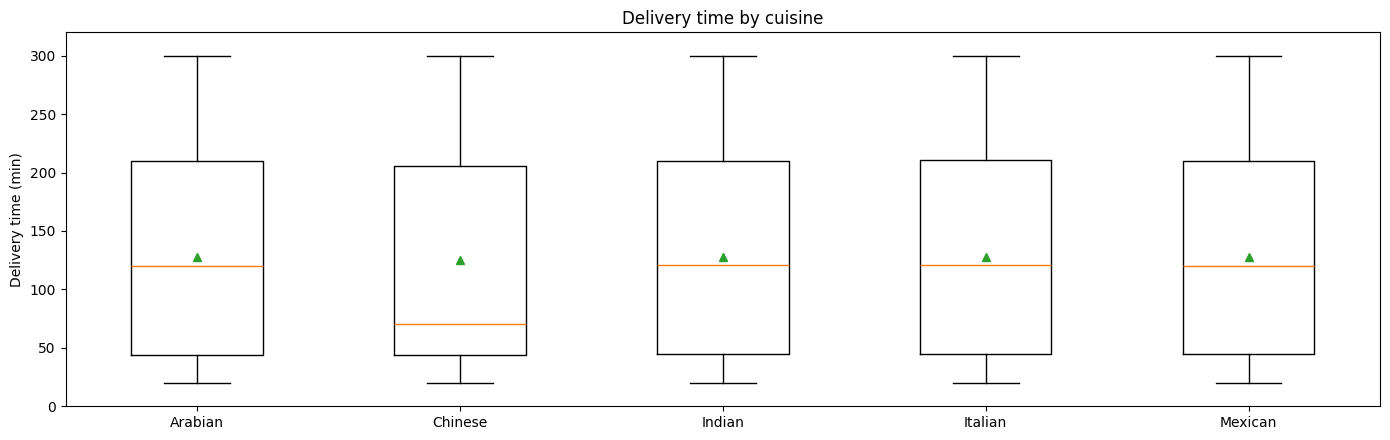

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

d = delivered.dropna(subset=["Delivery_Time_Min"])
cuisines = sorted(d["Cuisine_Type"].unique())

fig, axes = plt.subplots(figsize=(14, 4.5))
axes.boxplot([d.loc[d["Cuisine_Type"] == c, "Delivery_Time_Min"] for c in cuisines],
                tick_labels=cuisines, showmeans=True, whis=(0, 100))
axes.set_ylim(0, 320)
axes.set_ylabel("Delivery time (min)")
axes.set_title("Delivery time by cuisine")

plt.tight_layout()
plt.show()

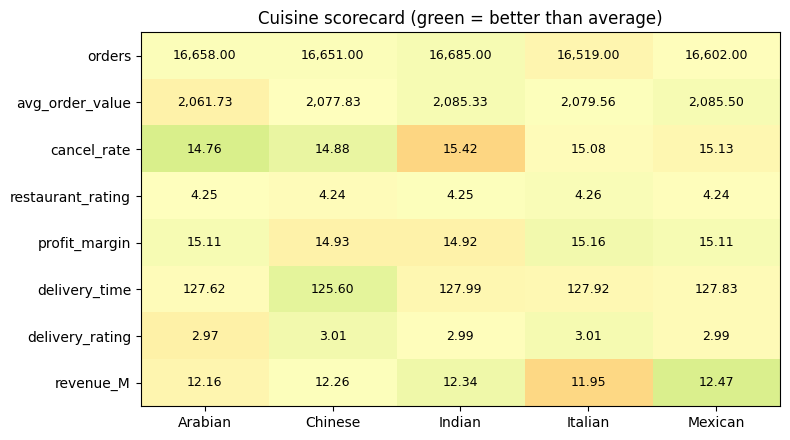

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

lower_is_better = ["cancel_rate", "delivery_time"]
score = index.T.copy()                                   # rows = metrics, columns = cuisines
dev = score - 100
dev.loc[lower_is_better] = -dev.loc[lower_is_better]    # flip so green always means better
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(dev, cmap="RdYlGn", vmin=-10, vmax=10, aspect="auto")
ax.set_xticks(range(dev.shape[1]), dev.columns)
ax.set_yticks(range(dev.shape[0]), dev.index)
for i in range(dev.shape[0]):
    for j in range(dev.shape[1]):
        ax.text(j, i, f"{perf.T.iloc[i, j]:,.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Cuisine scorecard (green = better than average)")
plt.tight_layout()
plt.show()

Peak hour demand analysis




In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
for c in ["City", "Cuisine_Type", "Order_Status", "Order_Day"]:
    raw[c] = raw[c].str.strip().str.title()
raw["Order_Date"] = pd.to_datetime(raw["Order_Date"], format="%m/%d/%Y", errors="coerce")

d = raw.dropna(subset=["Peak_Hour"]).copy()
d["Peak"] = d["Peak_Hour"].astype(bool)
d["Cancelled"] = d["Order_Status"] == "Cancelled"

delivered = d[~d["Cancelled"]]
compare = d.groupby("Peak").agg(
    orders=("Order_ID", "count"),
    avg_order_value=("Order_Value", "mean"),
    cancel_rate=("Cancelled", lambda s: s.mean() * 100),
    profit_margin=("Profit_Margin", lambda s: s.mean() * 100),
)
compare["delivery_time"] = delivered.groupby("Peak")["Delivery_Time_Min"].mean()
display(compare.round(2))


,orders,avg_order_value,cancel_rate,profit_margin,delivery_time
Peak,,,,,
False,33585,2082.57,14.95,15.06,128.09
True,33453,2081.38,15.19,15.01,126.76


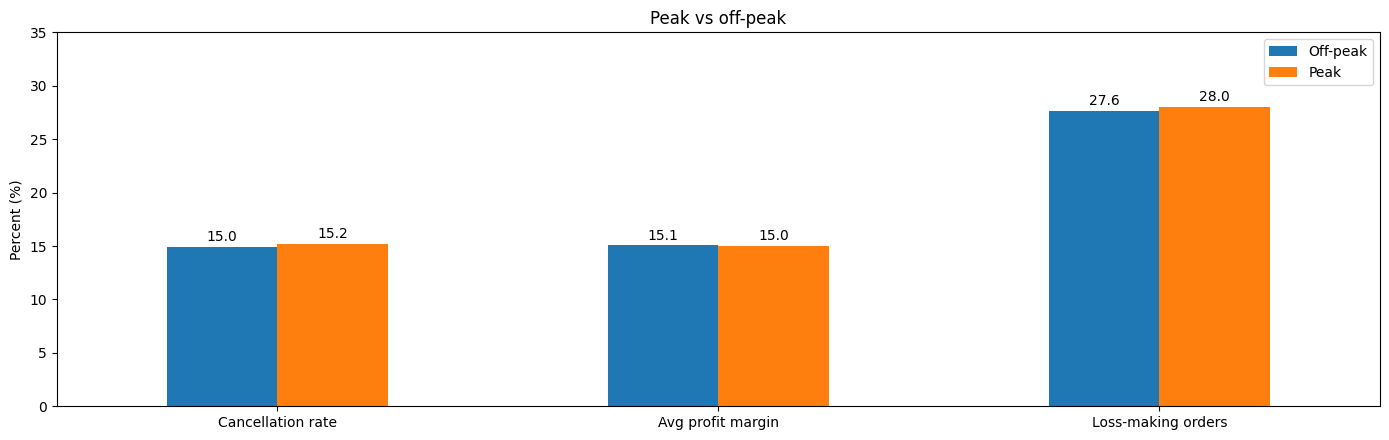

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(14, 4.5))



pct = d.groupby("Peak").agg(
    cancel_rate=("Cancelled", lambda s: s.mean() * 100),
    avg_margin=("Profit_Margin", lambda s: s.mean() * 100),
    loss_share=("Profit_Margin", lambda s: (s < 0).mean() * 100),
)
pct.index = ["Off-peak", "Peak"]
pct.T.plot(kind="bar", ax=axes, rot=0, color=["tab:blue", "tab:orange"])
axes.set_xticklabels(["Cancellation rate", "Avg profit margin", "Loss-making orders"])
axes.set_ylim(0, 35)
axes.set_ylabel("Percent (%)")
axes.set_title("Peak vs off-peak")
for c in axes.containers:
    axes.bar_label(c, fmt="%.1f", padding=2)

plt.tight_layout()
plt.show()

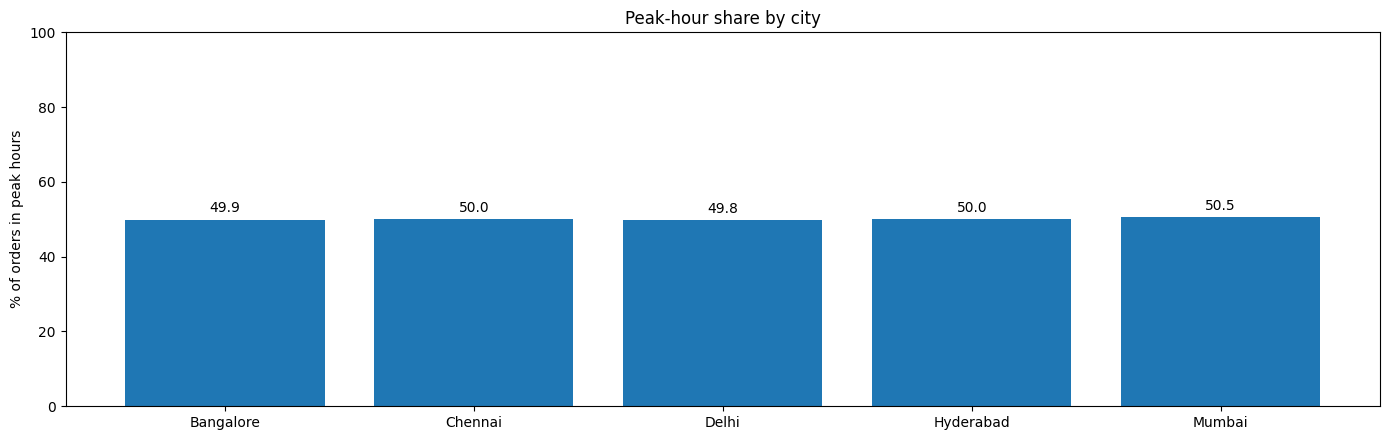

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

d = d.dropna(subset=["City", "Order_Date"]).copy()

fig, axes = plt.subplots(figsize=(14, 4.5))

# Bar chart: peak share by city
city_share = d.groupby("City")["Peak"].mean() * 100
bars = axes.bar(city_share.index, city_share.values)
axes.bar_label(bars, fmt="%.1f", padding=3)
axes.set_ylim(0, 100)
axes.set_ylabel("% of orders in peak hours")
axes.set_title("Peak-hour share by city")

plt.tight_layout()
plt.show()


/tmp/ipykernel_1475/632090060.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  delivered["Peak"] = delivered["Peak_Hour"].map({"Yes": True, "No": False}).fillna(False).astype(bool)


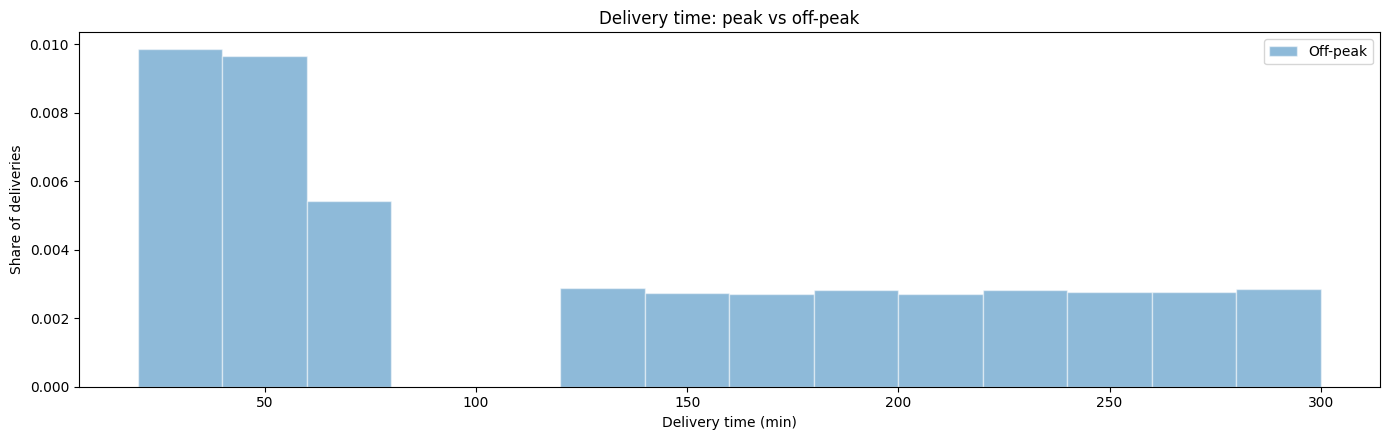

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Define 'delivered' directly from our clean 'df' in memory
delivered = df[df["Order_Status"] != "Cancelled"].copy()

# 2. Ensure Peak is mapped as boolean for the plotting logic
delivered["Peak"] = delivered["Peak_Hour"].map({"Yes": True, "No": False}).fillna(False)

fig, axes = plt.subplots(figsize=(14, 4.5))

# Histogram: delivery time, peak vs off-peak
dl = delivered.dropna(subset=["Delivery_Time_Min"])
for flag, label, color in [(False, "Off-peak", "tab:blue"), (True, "Peak", "tab:orange")]:
    axes.hist(dl.loc[dl["Peak"] == flag, "Delivery_Time_Min"], bins=np.arange(20, 320, 20),
                 alpha=0.5, density=True, label=label, color=color, edgecolor="white")
axes.set_title("Delivery time: peak vs off-peak")
axes.set_xlabel("Delivery time (min)")
axes.set_ylabel("Share of deliveries")
axes.legend()
plt.tight_layout()
plt.show()

In [ ]:
aw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["Payment_Mode"] = raw["Payment_Mode"].str.strip().str.title()
d = raw.dropna(subset=["Payment_Mode"]).copy()

counts = d["Payment_Mode"].value_counts()
display(counts)

,count
Payment_Mode,
Card,20094
Wallet,20086
Cod,19977
Upi,19932


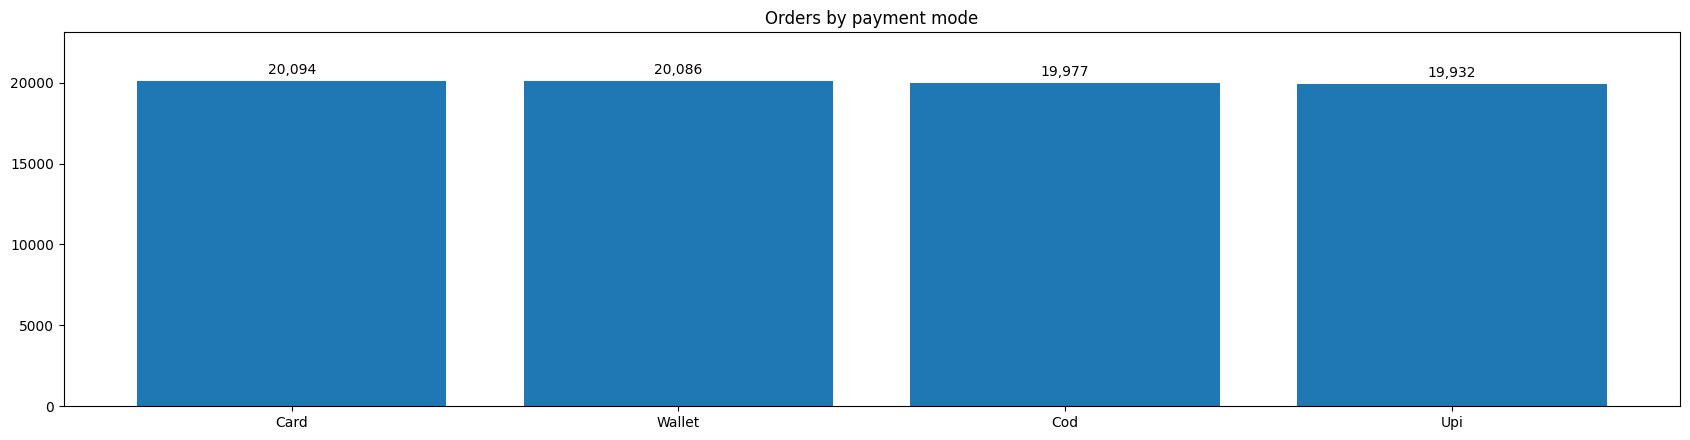

In [ ]:
fig, axes = plt.subplots(figsize=(17, 4.5))
bars = axes.bar(counts.index, counts.values)
axes.bar_label(bars, fmt="{:,.0f}", padding=3)
axes.set_ylim(0, counts.max() * 1.15)
axes.set_title("Orders by payment mode")
plt.tight_layout()
plt.show()

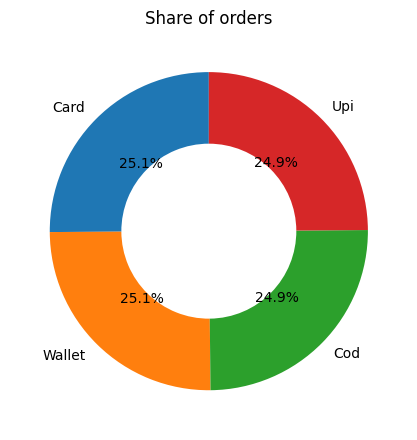

In [ ]:
fig, axes = plt.subplots(figsize=(17, 4.5))
axes.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
            wedgeprops=dict(width=0.45))
axes.set_title("Share of orders")
plt.tight_layout()
plt.show()

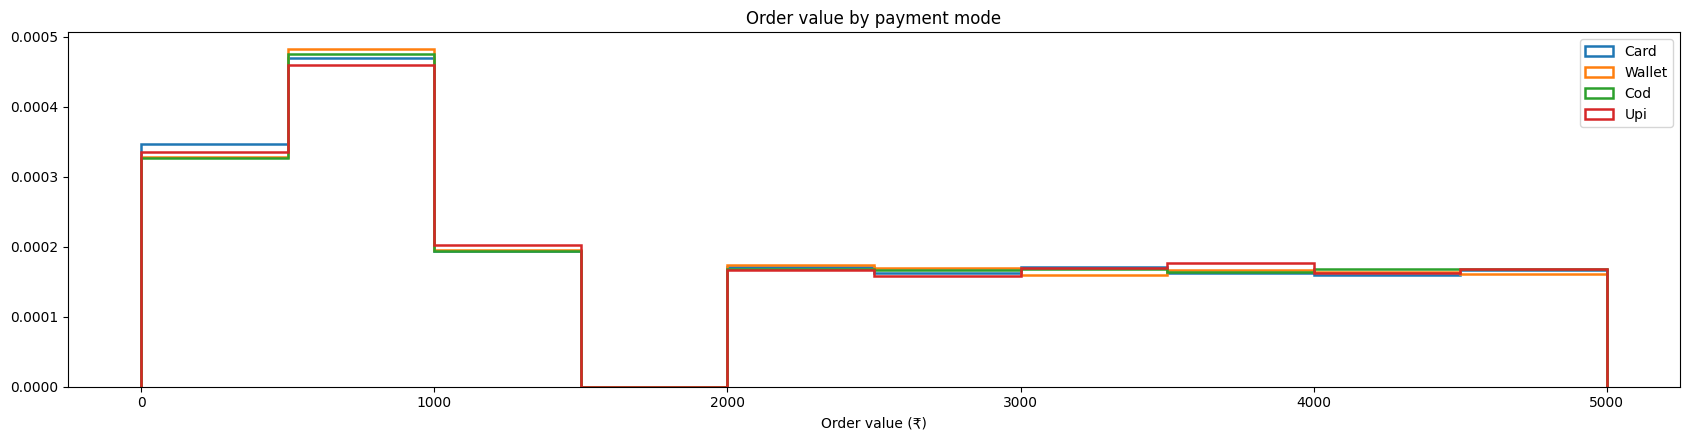

In [ ]:

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
raw["Payment_Mode"] = raw["Payment_Mode"].str.strip().str.title()
d = raw.dropna(subset=["Payment_Mode"]).copy()

counts = d["Payment_Mode"].value_counts()

fig, axes = plt.subplots(figsize=(17, 4.5))
for mode in counts.index:
    axes.hist(d.loc[d["Payment_Mode"] == mode, "Order_Value"].dropna(), bins=np.arange(0, 5500, 500),
                 histtype="step", density=True, linewidth=1.8, label=mode)
axes.set_title("Order value by payment mode")
axes.set_xlabel("Order value (₹)")
axes.legend()
plt.tight_layout()
plt.show()

Cancellation reason analysis




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")
for c in ["City", "Cuisine_Type", "Order_Status", "Order_Day", "Payment_Mode", "Cancellation_Reason"]:
    raw[c] = raw[c].str.strip().str.title()

cancelled = raw[raw["Order_Status"] == "Cancelled"].copy()
cancelled["Reason"] = cancelled["Cancellation_Reason"].fillna("Not Specified")
display(cancelled["Reason"].value_counts())

known = cancelled[cancelled["Reason"] != "Not Specified"]
order = ["Late Delivery", "Customer Cancelled", "Restaurant Issue"]


known = known.assign(Age_Group=pd.cut(known["Customer_Age"], [17, 24, 34, 44, 54, 100],
                                      labels=["18-24", "25-34", "35-44", "45-54", "55+"]))
by_age = pd.crosstab(known["Age_Group"], known["Reason"], normalize="index")[order] * 100
display(by_age.round(1))


,count
Reason,
Not Specified,6005
Late Delivery,3059
Customer Cancelled,2993
Restaurant Issue,2979


Reason,Late Delivery,Customer Cancelled,Restaurant Issue
Age_Group,,,
18-24,33.6,32.9,33.6
25-34,32.5,34.5,33.0
35-44,32.4,33.2,34.4
45-54,35.7,29.4,34.9
55+,38.1,30.3,31.6


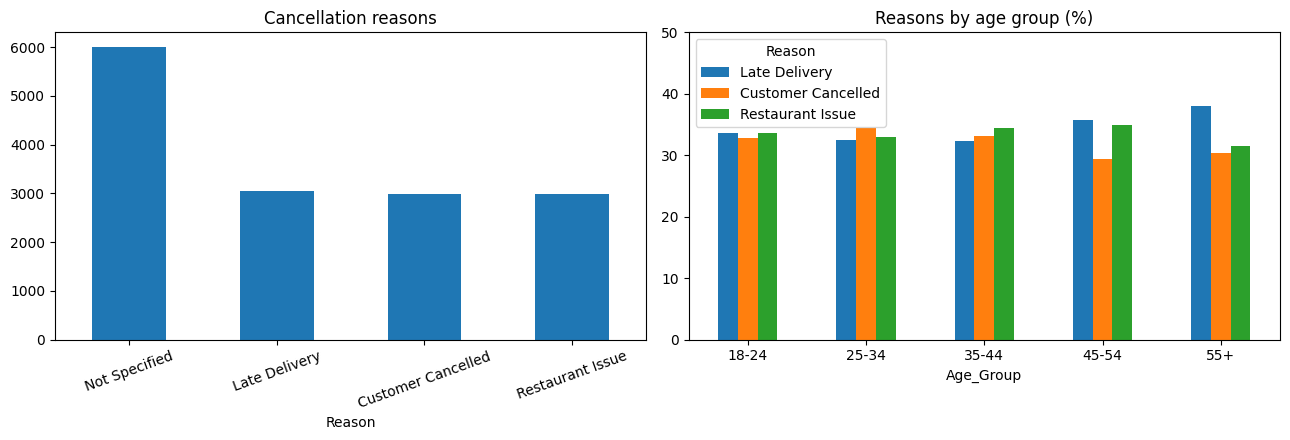

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cancelled["Reason"].value_counts().plot(kind="bar", ax=axes[0], rot=20, title="Cancellation reasons")
by_age.plot(kind="bar", ax=axes[1], rot=0, title="Reasons by age group (%)")
axes[1].set_ylim(0, 50)
plt.tight_layout()
plt.show()

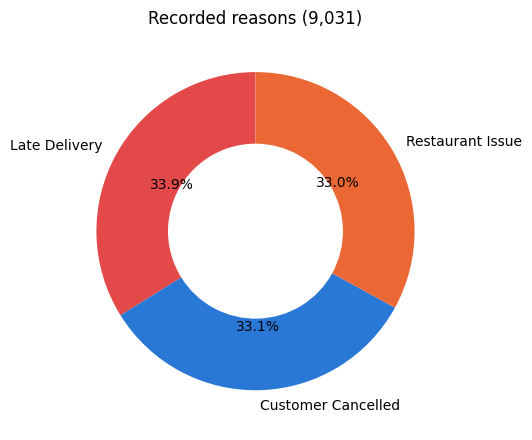

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(11, 4.5))

recorded = cancelled["Reason"][cancelled["Reason"] != "Not Specified"].value_counts()
axes.pie(recorded, labels=recorded.index, autopct="%1.1f%%", startangle=90,
            colors=["#e34948", "#2a78d6", "#eb6834"], wedgeprops=dict(width=0.45))
axes.set_title(f"Recorded reasons ({recorded.sum():,})")

plt.tight_layout()
plt.show()